# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Мищенко Мария Михайловна

**Файлы данных:** S17: `clients.csv`, `transactions.csv`

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [368]:
# проверка кодировок на нескольких строках данных
print("----- Clients table -----")
with open(RAW_CLIENTS, encoding='utf-8') as f:
    for _ in range(3):
        print(repr(f.readline()))

print("----- Transactions table -----")
with open(RAW_TXN, encoding='cp1251') as f:
    for _ in range(3):
        print(repr(f.readline()))

----- Clients table -----
'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,,Да,2024-08,,00805,Да\n'
'C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,,00256,Да\n'
----- Transactions table -----
'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990060;C004365;2023-12-05 14:19:43;145,82;RUB;Продукты;5411;Карта;успешно\n'
'990167;C005370;2023-12-10 10:57:55;1480,83;RUB;Продукты;5411;СБП;успешно\n'


**Вывод:** файл с клиентами читается как UTF-8, разделитель — ",", дробная часть — через точку, первая строка — заголовок. Параметры `read_csv` по умолчанию подходят. Файл с транзакциями имеет другую кодировку, разделитель - ";", дробная часть через запятую => явно указываем параметры, когда читаем этот файл.

In [369]:
clients_raw = pd.read_csv(RAW_CLIENTS)
clients = clients_raw.copy()
clients_raw.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,NaN,Да,2024-08,NaN,805,Да
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,NaN,256,Да
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,10.07.2019,03.11.2021,Зарплата в нашем банке,102900.0,Нет,NaN,NaN,198,Да
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,13.10.2024,08.02.2025,Зарплата в нашем банке,85100.0,Да,2024-04,NaN,927,Да
4,C004093,1992-10-13,Ж,СПб,Массовый,Базовый,Дебетовая,27.08.2015,24.09.2017,Зарплата в нашем банке,47900.0,Да,2024-03,NaN,171,Да


In [370]:
transactions_raw = pd.read_csv(RAW_TXN, encoding='cp1251', sep=';', decimal=',')
transactions = transactions_raw.copy()
transactions_raw.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990060,C004365,2023-12-05 14:19:43,145.82,RUB,Продукты,5411,Карта,успешно
1,990167,C005370,2023-12-10 10:57:55,1480.83,RUB,Продукты,5411,СБП,успешно
2,990142,C005487,2023-12-12,530.24,RUB,Продукты,5411,Карта,успешно
3,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе/рестораны,5812,Онлайн-банк,успешно
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

**Clients table**

In [11]:
print("Объём: ", clients.shape)
clients.head()

Объём:  (5715, 16)


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,NaN,Да,2024-08,NaN,805,Да
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,NaN,256,Да
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,10.07.2019,03.11.2021,Зарплата в нашем банке,102900.0,Нет,NaN,NaN,198,Да
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,13.10.2024,08.02.2025,Зарплата в нашем банке,85100.0,Да,2024-04,NaN,927,Да
4,C004093,1992-10-13,Ж,СПб,Массовый,Базовый,Дебетовая,27.08.2015,24.09.2017,Зарплата в нашем банке,47900.0,Да,2024-03,NaN,171,Да


In [12]:
clients_overview = pd.DataFrame({
    "dtype": clients.dtypes,
    "n_unique": clients.nunique(),
    "n_missing": clients.isna().sum(),
    'missing_%': (clients.isna().mean() * 100).round(2),
})
clients_overview

,dtype,n_unique,n_missing,missing_%
client_id,str,5660,0,0.00
birth_date,str,4846,0,0.00
gender,str,2,0,0.00
city,str,17,0,0.00
segment,str,4,0,0.00
loyalty_tier,str,4,0,0.00
card_type,str,3,0,0.00
registration_date,str,3267,0,0.00
card_open_date,str,2642,0,0.00
income_source,str,3,0,0.00


In [546]:
clients.describe(include=['float64'])

,monthly_income
count,5161.000000
mean,95110.636524
std,83253.057907
min,-999.000000
25%,52600.000000
50%,72800.000000
75%,108000.000000
max,991300.000000


**Transactions table**

In [14]:
print("Объём: ", transactions.shape)
transactions.head()

Объём:  (616993, 9)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990060,C004365,2023-12-05 14:19:43,145.82,RUB,Продукты,5411,Карта,успешно
1,990167,C005370,2023-12-10 10:57:55,1480.83,RUB,Продукты,5411,СБП,успешно
2,990142,C005487,2023-12-12,530.24,RUB,Продукты,5411,Карта,успешно
3,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе/рестораны,5812,Онлайн-банк,успешно
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно


In [15]:
transactions_overview = pd.DataFrame({
    "dtype": transactions.dtypes,
    "n_unique": transactions.nunique(),
    "n_missing": transactions.isna().sum()
})
transactions_overview

,dtype,n_unique,n_missing
txn_id,int64,615493,0
client_id,str,5991,0
txn_datetime,str,560854,0
amount,float64,324291,0
currency,str,3,0
category,str,12,0
mcc_code,int64,9,0
channel,str,4,0
status,str,3,0


In [16]:
transactions.describe(include=['float64'])

,amount
count,616993.000000
mean,1887.642972
std,2745.238445
min,-62286.590000
25%,468.710000
50%,1069.640000
75%,2275.320000
max,116052.630000


### 2.2. Дубли

In [17]:
print("Полные дубликаты строк в clients: ", clients.duplicated().sum())
print("Полные дубликаты строк в transactions: ", transactions.duplicated().sum())

Полные дубликаты строк в clients:  40
Полные дубликаты строк в transactions:  1283


### 2.3. Соответствие данных описанию полей из задания

**Clients**

In [18]:
clients.columns

Index(['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source',
       'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'branch_code', 'marketing_opt_in'],
      dtype='str')

In [19]:
# 1. проверка соответсвия категорий в признаках, для которых указан чёткий список возможных значений категории
multi_category_columns = ["segment", "loyalty_tier", "card_type", "satisfaction_score"]
for col in multi_category_columns:
    print(f"{col}: {clients[col].unique().tolist()}\n")
    display(pd.DataFrame({
        'count': clients[col].value_counts(dropna=False),
        'freq': clients[col].value_counts(normalize=True).round(3)
    }))

# 2. проверка значений булевых признаков
boolean_columns = ["gender", "has_mobile_app", "marketing_opt_in"]
for bool_col in boolean_columns:
    print(f"\n{bool_col}: {clients[bool_col].unique().tolist()}\n")
    display(pd.DataFrame({
            'count': clients[bool_col].value_counts(dropna=False),
            'freq': clients[bool_col].value_counts(normalize=True).round(3)
    }))

segment: ['Премиальный', 'Зарплатный', 'Массовый', 'Private']



,count,freq
segment,,
Массовый,2956,0.517
Зарплатный,1604,0.281
Премиальный,921,0.161
Private,234,0.041


loyalty_tier: ['Серебро', 'Золото', 'Базовый', 'Платина']



,count,freq
loyalty_tier,,
Базовый,2856,0.500
Серебро,1605,0.281
Золото,936,0.164
Платина,318,0.056


card_type: ['Кредитная', 'Дебетовая', 'Премиальная']



,count,freq
card_type,,
Дебетовая,4036,0.706
Кредитная,1192,0.209
Премиальная,487,0.085


... (4 outputs left out)


has_mobile_app: ['Да', 'Нет']



,count,freq
has_mobile_app,,
Да,3513,0.615
Нет,2202,0.385



marketing_opt_in: ['Да', 'Нет']



,count,freq
marketing_opt_in,,
Да,5030,0.88
Нет,685,0.12


In [20]:
# 3. анализ значений в другие не числовых столбцах 
print(clients['city'].value_counts())

city
Москва                1134
Екатеринбург           643
Санкт-Петербург        619
Новосибирск            570
Нижний Новгород        565
Казань                 528
МОСКВА                 195
г. Москва              191
 москва                185
казань                 157
г. Новосибирск         157
г.Екатеринбург         151
Н. Новгород            150
ЕКАТЕРИНБУРГ           141
Санкт Петербург        125
г. Санкт-Петербург     105
СПб                     99
Name: count, dtype: int64


**Transactions**

In [21]:
transactions.columns

Index(['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'mcc_code', 'channel', 'status'], dtype='str')

In [22]:
# 1. проверка соответсвия категорий в признаках, для которых указан чёткий список возможных значений категории
multi_category_columns = ["channel", "status"]
for col in multi_category_columns:
    print(f"{col}: {transactions[col].unique()}\n")
    display(pd.DataFrame({
        'count': transactions[col].value_counts(dropna=False),
        'freq': transactions[col].value_counts(normalize=True).round(3)
    }))

channel: <StringArray>
['Карта', 'СБП', 'Онлайн-банк', 'Токен']
Length: 4, dtype: str



,count,freq
channel,,
Карта,315225,0.511
СБП,109742,0.178
Токен,104081,0.169
Онлайн-банк,87945,0.143


status: <StringArray>
['успешно', 'отклонено', 'возврат']
Length: 3, dtype: str



,count,freq
status,,
успешно,597249,0.968
отклонено,12169,0.020
возврат,7575,0.012


In [23]:
# 2. проверка других нечисловых столбцов
print(transactions['currency'].value_counts())
print("Кол-во возможных значений кода торговой точки: ",len(transactions['mcc_code'].value_counts()))

print(transactions['category'].value_counts())
print("Кол-во возможных значений категорий: ",len(transactions['category'].value_counts()))

currency
RUB    614514
USD      1290
EUR      1189
Name: count, dtype: int64
Кол-во возможных значений кода торговой точки:  9
category
Продукты               162838
Одежда и обувь          69436
Транспорт               65160
АЗС                     56577
Кафе и рестораны        47774
Развлечения и досуг     46552
Аптеки                  44667
Онлайн-сервисы          43467
Связь и интернет        29193
Связь и Интернет        19565
кафе и рестораны        15965
Кафе/рестораны          15799
Name: count, dtype: int64
Кол-во возможных значений категорий:  12


### 2.4. Связь между таблицами

In [24]:
# 1. совпадение типов 
print("Совпадение типов у полей с id: ", clients["client_id"].dtype == transactions["client_id"].dtype)
print(transactions["client_id"].dtype)

# 2. клиенты, которые есть в clients, но отсутствуют в transactions
clients_without_transactions = clients[~clients["client_id"].isin(transactions["client_id"])]
print("Кол-во клиентов без транзакций: ", len(clients_without_transactions))
display(clients_without_transactions)

# 3. транзакции клиентов, который нет в clients
empty_transactions = transactions[~transactions["client_id"].isin(clients["client_id"])]
print("Кол-во транзакций от клиентов не из clients: ", len(empty_transactions))
display(empty_transactions)

Совпадение типов у полей с id:  True
str
Кол-во клиентов без транзакций:  9


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
487,C000178,1937-05-31,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,31.01.2025,06.05.2025,Не указан,48500.0,Нет,NaN,3.0,420,Да
2235,C001665,1951-03-19,Ж,Нижний Новгород,Массовый,Серебро,Кредитная,13.09.2019,22.04.2025,Не указан,50100.0,Да,2024-11,1.0,731,Да
2460,C002859,1971-05-12,Ж,МОСКВА,Массовый,Базовый,Дебетовая,28.12.2023,14.04.2025,Не указан,47200.0,Нет,NaN,5.0,184,Да
2957,C000855,1968-03-07,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,07.08.2019,08.05.2025,Не указан,59200.0,Да,2024-11,NaN,721,Да
3175,C004481,1971-11-07,М,Москва,Премиальный,Золото,Дебетовая,03.07.2020,11.05.2025,Зарплата в нашем банке,292200.0,Да,2024-09,NaN,113,Да
3191,C005667,1994-10-07,М,Новосибирск,Зарплатный,Серебро,Дебетовая,03.02.2025,25.04.2025,Зарплата в нашем банке,53500.0,Да,2024-12,NaN,508,Да
5247,C005283,1949-03-21,М,Екатеринбург,Массовый,Базовый,Дебетовая,06.02.2021,30.04.2025,Не указан,NaN,Да,2024-10,NaN,883,Нет
5277,C002181,1975-10-30,Ж,г. Москва,Массовый,Базовый,Дебетовая,25.08.2023,13.05.2025,Зарплата в нашем банке,41400.0,Нет,NaN,NaN,538,Да
5554,C003462,1936-08-20,Ж,москва,Зарплатный,Серебро,Дебетовая,17.07.2024,29.04.2025,Зарплата в нашем банке,129600.0,Нет,NaN,NaN,652,Да


Кол-во транзакций от клиентов не из clients:  30422


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно
16,100013,C003574,2024-01-01 05:18:07,4912.64,RUB,Аптеки,5912,Карта,успешно
24,100021,C004476,2024-01-01,1211.23,RUB,Продукты,5411,Карта,успешно
46,100043,C002888,2024-01-01 07:48:53,805.26,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно
51,100048,C005228,2024-01-01 07:55:00,906.36,RUB,Кафе и рестораны,5812,СБП,успешно
...,...,...,...,...,...,...,...,...,...
573132,990032,C004721,2025-05-16,1354.11,RUB,АЗС,5541,Онлайн-банк,успешно
616918,990126,C003390,2025-08-11 17:58:31,744.06,RUB,Продукты,5411,Карта,успешно
616937,990156,C001425,2025-10-18 16:48:07,100.62,RUB,Транспорт,4111,Карта,успешно
616959,990189,C003390,2026-01-19,407.60,RUB,Связь и Интернет,4814,Токен,успешно


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

**Выводы:**

I. Таблица `clients`
1. Кол-во строк: 5715
2. Три признака представлены числовым типом данных, остальные имеют тип str. Столбцы, по смыслу являющиеся категориями, также хранятся как строки.
3. Пропущено больше половины значений в `satisfaction_score`(~59%), также пропуски в `monthly_income`(~10%), `app_last_login`(~39%).
4. Минимальное значение `monthly_income` отрицательное - странное значение для этого столбца; среднее значение больше медианы, а максимальное больше медианы в ~13 раз.
5. 40 полных дубликатов строк.
6. Признаки с явно указанными в условии категориями не имеют порпусков, а их категории соответствуют указанным в задании, но хранятся они как строки.
7. Бинарные по смыслу признаки хранятся как строки.
8. В `city` один и тот же город записан разными способами, что значительно увеличивает кол-во уникальных значений этого столбца.


II. Таблица `transactions`
1. Кол-во строк: 616993
2. `txn_id`, `amount`, `mcc_code` хранятся числовым типом данных, остальные - строки.
3. В `amount`: среднее и медиана отличаются не сильно; минимальное значение отрицательное - подозрительное значение, если ему соответвует статус "успешно", но может быть вполне нормальным и логичным, если в статусе опреации отклонено/возврат; максимальное значение ~116k при медиане ~1.8k => правосторонняя асимметрия и, возможно, выбросы.
4. Пропусков в данных нет
5. 1283 полных дубликатов строк
6. Признаки с явно указанными в условии категориями (`channel`, `status`) не имеют порпусков, а их категории соответствуют указанным в задании. По смыслу являются категориями, но хранятся они как строки. 
7. В столбце `category` одни и те же категории записаны различными способами, что некорректно увеличивает число уникальных категорий: становится 12 вместо указанных 9. Хранится типом str.


III.  Связь между таблицами
- Идентификатор, связывающий таблицы - client_id, имеет тип данных str в обеих таблицах.
- Таблицы `clients` и `transactions` имею разное кол-во уникальных клиентов(client_id). В `clients` их 5660, а в `transactions` - 5991. В таблице `clients` присутствуют 9 клиентов, не совершавших вообще никаких транзакций, а в таблице `transactions` - 30422 транзакций соответствуют клиентам, которых нет в таблице clients. Это важно будет учитывать в случае соединения таблиц, чтобы корректно его выполнить.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [371]:
# clients
clients = clients.assign(
    birth_date = pd.to_datetime(clients["birth_date"], format="%Y-%m-%d"),
    registration_date = pd.to_datetime(clients["registration_date"], format="%d.%m.%Y"),
    card_open_date = pd.to_datetime(clients["card_open_date"], format="%d.%m.%Y"),
    app_last_login = pd.to_datetime(clients["app_last_login"], format="%Y-%m")
)

# transactions
transactions = transactions.assign(
    txn_datetime = pd.to_datetime(transactions["txn_datetime"], format="ISO8601", errors="coerce")
)

### 3.2. Категориальные признаки

In [372]:
# clients
clients = clients.assign(
    has_mobile_app = clients["has_mobile_app"].map({"Да": True, "Нет": False}),
    marketing_opt_in = clients["marketing_opt_in"].map({"Да": True, "Нет": False}),
    gender = clients["gender"].astype("category"),
    segment = clients["segment"].astype("category"),
    loyalty_tier = clients["loyalty_tier"].astype("category"),
    card_type = clients["card_type"].astype("category"),
    satisfaction_score = clients["satisfaction_score"].astype("category")
)

city_map = {
    "г. москва": "москва",
    "г. новосибирск": "новосибирск",
    "г.екатеринбург": "екатеринбург",
    "н. новгород": "нижний новгород",
    "санкт петербург": "санкт-петербург",
    "г. санкт-петербург": "санкт-петербург",
    "спб": "санкт-петербург"
}
clients["city"] = (clients["city"].str.strip()
                   .str.lower()
                   .replace(city_map)
                   .str.title())

In [373]:
print(clients.dtypes)
print(f"\n{clients['city'].value_counts()}")

client_id                        str
birth_date            datetime64[us]
gender                      category
city                             str
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                  bool
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    int64
marketing_opt_in                bool
dtype: object

city
Москва             1705
Санкт-Петербург     948
Екатеринбург        935
Новосибирск         727
Нижний Новгород     715
Казань              685
Name: count, dtype: int64


In [374]:
# transactions
transactions = transactions.assign(
    channel = transactions["channel"].astype("category"),
    status = transactions["status"].astype("category"),
    currency = transactions["currency"].astype("category")
)

category_map = {
    "кафе/рестораны": "кафе и рестораны"
}
transactions["category"] = (transactions["category"].str.strip()
                                                    .str.lower()
                                                    .replace(category_map)
                                                    .str.capitalize()).astype("category")

In [375]:
print(f"{transactions.dtypes}\n")
print(transactions["category"].value_counts())

txn_id                   int64
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
mcc_code                 int64
channel               category
status                category
dtype: object

category
Продукты               162838
Кафе и рестораны        79538
Одежда и обувь          69436
Транспорт               65160
Азс                     56577
Связь и интернет        48758
Развлечения и досуг     46552
Аптеки                  44667
Онлайн-сервисы          43467
Name: count, dtype: int64


In [376]:
# # сэкономленная память в результате преобразования типов
# mem_before = transactions_raw.memory_usage(deep=True).sum() / 2**20
# mem_after = transactions.memory_usage(deep=True).sum() / 2**20
# print(f'Память: {mem_before:.2f} МБ -> {mem_after:.2f} МБ')

### 3.3. Дубликаты

Полные дубли строк в данном случае не является реальным повторением события, а скорее просто сбой/ошибка, т.к. это полное совпадение информации о клиенте/транзакции, включая их id, поэтому такие дубли удаляем в обеих таблицах. 

In [377]:
# полные дубли
clients_clean = clients.drop_duplicates()
print("Clients new shape: ", clients_clean.shape)

transactions_clean = transactions.drop_duplicates()
print("Transactions new shape: ", transactions_clean.shape)

Clients new shape:  (5675, 16)
Transactions new shape:  (615710, 9)


In [378]:
# дубли id
print(f"Кол-во уникальных client_id: {len(clients_clean.client_id.unique())}")
print(f"Кол-во уникальных txn_id: {len(transactions_clean.txn_id.unique())}")

Кол-во уникальных client_id: 5660
Кол-во уникальных txn_id: 615493


Кол-во уникальных id меньше, чем кол-во строк в уже очищенных от полных дубликатов строк таблицах, это странно, т.к. id должны быть уникальными. Посмотрим, что за дубликаты для каждой таблицы

**Transactions**

In [379]:
dup_transactions = transactions_clean[transactions_clean.duplicated(subset=["txn_id"], keep=False)].sort_values(by=['txn_id'])
print(dup_transactions)

def show_differences(group):
    diff_cols = group.nunique() > 1
    diff_cols['txn_id'] = True
    return group.loc[:, diff_cols]

result = dup_transactions.groupby('txn_id', as_index=False).apply(show_differences).reset_index(drop=True)
result

        txn_id client_id        txn_datetime   amount currency        category  mcc_code channel   status
5120    105108   C000922 2024-01-06 15:15:44   222.83      RUB  Онлайн-сервисы      5815   Карта  успешно
5121    105108   C000922 2024-01-06 00:00:00   222.83      RUB  Онлайн-сервисы      5815   Карта  успешно
9655    109631   C001425 2024-01-12 08:00:29  2696.38      RUB        Продукты      5411     СБП  успешно
9656    109631   C001425 2024-01-12 00:00:00  2696.38      RUB        Продукты      5411     СБП  успешно
17956   117904   C002925 2024-01-21 12:41:23   936.53      RUB             Азс      5541   Карта  успешно
...        ...       ...                 ...      ...      ...             ...       ...     ...      ...
612947  715228   C001811 2025-06-26 19:54:52  7238.65      RUB  Одежда и обувь      5651   Карта  успешно
614012  716290   C001663 2025-06-28 00:00:00   804.68      RUB        Продукты      5411   Карта  успешно
614013  716290   C001663 2025-06-28 09:04:27  

,txn_datetime
0,2024-01-06 15:15:44
1,2024-01-06 00:00:00
2,2024-01-12 08:00:29
3,2024-01-12 00:00:00
4,2024-01-21 12:41:23
...,...
429,2025-06-26 19:54:52
430,2025-06-28 00:00:00
431,2025-06-28 09:04:27
432,2025-06-30 16:20:08


Видно, что дубли по `txn_id` появляются из-за по-разному записанных дат транзакций: где-то с указанием точного времени, где-то просто датой. Все остальные признаки идентичны, поэтому можем удалить строки, в которых `txn_datetime` записана менее точно - т.е. где время 00:00:00.

In [380]:
transactions_clean["txn_day"] = transactions_clean["txn_datetime"].dt.normalize()
transactions_clean["has_exact_time"] = transactions_clean["txn_datetime"] != transactions_clean["txn_day"]
match_cols = [col for col in transactions_clean.columns if col not in ("txn_datetime", "has_exact_time")]

transactions_clean = (transactions_clean.sort_values("has_exact_time", ascending=False, kind="stable")
         .drop_duplicates(subset=match_cols, keep="first")
         .sort_index()
         .drop(columns=["txn_day", "has_exact_time"])
)

In [381]:
print(len(transactions_clean) == transactions_clean["txn_id"].nunique())
print(f"Transactions shape: {transactions_clean.shape}")

True
Transactions shape: (615493, 9)


**Clients**

In [382]:
dup_clients = clients_clean[clients_clean.duplicated(subset=["client_id"], keep=False)].sort_values(by=['client_id'])
dup_clients

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
1110,C000541,1952-04-19,М,Екатеринбург,Private,Серебро,Дебетовая,2017-04-18,2019-08-26,Зарплата в нашем банке,76100.0,True,2024-01-01,NaN,884,True
4132,C000541,1952-04-19,М,Новосибирск,Зарплатный,Серебро,Дебетовая,2017-04-18,2019-08-26,Зарплата в нашем банке,76100.0,True,2024-01-01,NaN,884,True
2785,C000685,1985-01-18,Ж,Екатеринбург,Массовый,Серебро,Дебетовая,2013-05-24,2018-10-02,Зарплата в другом банке,29700.0,False,NaT,5.0,924,True
2644,C000685,1985-01-18,Ж,Нижний Новгород,Зарплатный,Серебро,Дебетовая,2013-05-24,2018-10-02,Зарплата в другом банке,29700.0,False,NaT,5.0,924,True
4837,C000897,1983-05-18,Ж,Новосибирск,Зарплатный,Базовый,Дебетовая,2011-12-27,2016-03-19,Зарплата в другом банке,45100.0,True,2024-10-01,4.0,459,True
2966,C000897,1983-05-18,Ж,Москва,Массовый,Базовый,Дебетовая,2011-12-27,2016-03-19,Зарплата в другом банке,45100.0,True,2024-10-01,4.0,459,True
3357,C001195,1995-08-19,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2020-05-10,2021-02-04,Не указан,114000.0,True,2025-01-01,NaN,759,False
3342,C001195,1995-08-19,М,Казань,Массовый,Серебро,Дебетовая,2020-05-10,2021-02-04,Не указан,114000.0,True,2025-01-01,NaN,759,False
4285,C001558,1949-01-06,Ж,Москва,Массовый,Серебро,Дебетовая,2011-11-27,2017-05-05,Зарплата в другом банке,42600.0,True,2024-06-01,NaN,472,True
2891,C001558,1949-01-06,Ж,Новосибирск,Премиальный,Серебро,Дебетовая,2011-11-27,2017-05-05,Зарплата в другом банке,42600.0,True,2024-06-01,NaN,472,True


In [383]:
def show_differences_clients(group):
    diff_cols = group.nunique() > 1
    diff_cols['client_id'] = True
    return group.loc[:, diff_cols]

dup_clients.groupby('client_id', as_index=False).apply(show_differences_clients).reset_index(drop=True)

,city,segment
0,Екатеринбург,Private
1,Новосибирск,Зарплатный
2,Екатеринбург,Массовый
3,Нижний Новгород,Зарплатный
4,Новосибирск,Зарплатный
5,Москва,Массовый
6,Санкт-Петербург,NaN
7,Казань,NaN
8,Москва,Массовый
9,Новосибирск,Премиальный


Для дубликатов по клиентам не совпадают значения в `city` и могут не совпадать значения в `segment`. Можно либо предположить, что каждая вторая запись либо была внесена случайно, и тогда можно оставить первые записи о клиентах с повторяющимися id, а вторые удалить; либо что клиент поменял свой город проживания/уровень лояльности, но тогда при смене города мог бы поменяться и код отделения обслуживания `branch_code`, если это именно код отделения, в котором обслуживался клиент в последний раз(если код отделения, в котором был открыт указанный счёт, то мог и не поменяться), изменение сегмента скорее всего сопровождалось бы изменением месячного дохода `monthly_income`, а в найденных дублях эти значения совпадают. Исходя из этого и того, что актуальности записей нет, предполагаю, что вторые записи являются ошибками и оставляю только строки с первой встречей `client_id`.

In [384]:
clients_clean = clients_clean.drop_duplicates(subset=["client_id"], keep='first')
clients_clean

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,Москва,Премиальный,Серебро,Кредитная,2020-11-19,2022-04-03,Не указан,NaN,True,2024-08-01,NaN,805,True
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,2012-06-16,2017-08-31,Зарплата в нашем банке,61600.0,True,2025-05-01,NaN,256,True
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,2019-07-10,2021-11-03,Зарплата в нашем банке,102900.0,False,NaT,NaN,198,True
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,2024-10-13,2025-02-08,Зарплата в нашем банке,85100.0,True,2024-04-01,NaN,927,True
4,C004093,1992-10-13,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,2015-08-27,2017-09-24,Зарплата в нашем банке,47900.0,True,2024-03-01,NaN,171,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5710,C000756,1960-11-28,М,Москва,Премиальный,Золото,Премиальная,2019-10-02,2021-04-03,Не указан,135200.0,True,2024-05-01,5.0,506,True
5711,C002224,1981-04-12,Ж,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2013-11-30,2018-06-18,Зарплата в нашем банке,45800.0,True,2024-05-01,NaN,129,True
5712,C002374,1936-11-28,М,Москва,Массовый,Базовый,Кредитная,2020-03-18,2024-07-21,Зарплата в другом банке,58100.0,False,NaT,NaN,317,False
5713,C001384,1985-10-24,М,Екатеринбург,Массовый,Базовый,Дебетовая,2021-05-11,2021-07-27,Зарплата в другом банке,46100.0,True,2024-10-01,NaN,412,True


In [385]:
print(len(clients_clean) == clients_clean["client_id"].nunique())
print(f"Clients shape: {clients_clean.shape}")

True
Clients shape: (5660, 16)


### 3.4. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

**Поля с пропусками:**

В clients: `monthly_income`, `app_last_login`, `satisfaction_score`

**1. monthly_income**

In [386]:
print("Доля пропусков: ", (clients_clean["monthly_income"].isna().mean() * 100).round(2),"%")
print(f"Статистика по столбцу:\n{clients_clean['monthly_income'].describe()}")

Доля пропусков:  9.79 %
Статистика по столбцу:
count      5106.000000
mean      95142.306678
std       83344.091254
min        -999.000000
25%       52700.000000
50%       72800.000000
75%      107975.000000
max      991300.000000
Name: monthly_income, dtype: float64


В `monthly_income` есть отрицательные значения, что является кандидатом для более подробного изучения. Посмотрим подробнее

In [387]:
neg_income = clients_clean.loc[clients_clean["monthly_income"] < 0]
print("Уникальные: ", neg_income["monthly_income"].value_counts())
print("Частоты сегментов: \n")
print(neg_income["segment"].value_counts())

Уникальные:  monthly_income
-999.0    45
Name: count, dtype: int64
Частоты сегментов: 

segment
Массовый       24
Зарплатный     13
Private         4
Премиальный     4
Name: count, dtype: int64


Отрицательная запись "-999.0" встречается в каждом из сегментов, доля таких значений маленькая. Учитывая, что это единственное отрицательно значение, то оно скорее является индикатором о недоступности инфомации и доходе(не был указан или не известен по другим причинам). Возможно, это специальное значение, которое использовалось при заполнении информации о клиентах. Поэтому по смыслу эти значения скорее являются пропусками, заменяю на NaN. 

In [388]:
clients_clean["monthly_income"] = (clients_clean["monthly_income"].replace(-999.0, np.nan))

In [389]:
print(clients_clean.groupby("segment")["monthly_income"].describe())
print("Асимметрия: ", clients_clean["monthly_income"].skew())

              count           mean            std    min       25%       50%       75%       max
segment                                                                                         
Private       201.0  379668.231343  164638.808436  209.6  267000.0  348100.0  476500.0  991300.0
Зарплатный   1501.0   82726.399734   34808.473946   30.7   59400.0   78500.0  101200.0  377100.0
Массовый     2535.0   62227.223748   27318.995477   29.2   44700.0   59200.0   76150.0  262600.0
Премиальный   824.0  154866.408010   67283.927416   77.3  111775.0  147100.0  186975.0  505400.0
Асимметрия:  3.636549680568111


Также инетерсно заметить, что минимальные значения отличаются от значений первого квантиля в ~1000 раз. Вероятнее всего часть значений записано в тысячах(209.6 тыс.) вместо 209600, иначе значение ежемесячного дохода в 209.6 единиц валюты выглядит странно. Такие значения так же являются кандидатами для доп проверки. Проверим их до того, как считать статистики и решать, как заполнять пропуски.

Домножим такие значения на 1000 и проверим, будут ли клиенты после этого попадать в границы для своего сегмента. Если да - гипотеза про то, что числа ошибочно записаны не в том масштабе, подтверждается.

In [390]:
threshold = 1000
ok_clients = clients_clean[clients_clean["monthly_income"] >= threshold]
not_ok_clients = clients_clean[(clients_clean["monthly_income"] < threshold) & (clients_clean["monthly_income"] > 0)]

print(ok_clients.groupby("segment")["monthly_income"].describe())
print(not_ok_clients.groupby("segment")["monthly_income"].describe())

              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       198.0  385414.141414  159045.438395  76100.0  270150.0  349200.0  478225.0  991300.0
Зарплатный   1471.0   84411.964650   33077.320358  22600.0   60650.0   79200.0  101450.0  377100.0
Массовый     2460.0   64122.195122   25449.328073  15100.0   46075.0   59900.0   76700.0  262600.0
Премиальный   803.0  158912.079701   63266.410868  29400.0  114400.0  148100.0  188500.0  505400.0
             count        mean         std    min     25%    50%      75%    max
segment                                                                         
Private        3.0  438.166667  241.673050  209.6  311.70  413.8  552.450  691.1
Зарплатный    30.0   77.533333   28.704251   30.7   58.55   69.4   96.625  156.8
Массовый      75.0   72.162667   24.940382   29.2   53.85   68.9   82.400  141.2
П

In [391]:
print((not_ok_clients.assign(inc_fixed=not_ok_clients["monthly_income"] * 1000).groupby("segment")["inc_fixed"].describe()))

             count           mean            std       min       25%       50%       75%       max
segment                                                                                           
Private        3.0  438166.666667  241673.050490  209600.0  311700.0  413800.0  552450.0  691100.0
Зарплатный    30.0   77533.333333   28704.250957   30700.0   58550.0   69400.0   96625.0  156800.0
Массовый      75.0   72162.666667   24940.381742   29200.0   53850.0   68900.0   82400.0  141200.0
Премиальный   21.0  167628.571429   79672.191779   77300.0  111400.0  140400.0  193200.0  379300.0


Полученные значения для каждого из сегментов лежат в правильных границах => гипотеза о некорректной записи подтвердилась, домножаем на 1000.

In [392]:
mask = (clients_clean["monthly_income"] < 1000) & (clients_clean["monthly_income"] > 0)
clients_clean.loc[mask, "monthly_income"] *= 1000

In [393]:
print(clients_clean.groupby("segment")["monthly_income"].describe())
print("Асимметрия: ", clients_clean["monthly_income"].skew())

              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       201.0  386201.492537  159816.137320  76100.0  270000.0  349900.0  478800.0  991300.0
Зарплатный   1501.0   84274.483678   33001.268589  22600.0   60600.0   79100.0  101400.0  377100.0
Массовый     2535.0   64360.078895   25466.068081  15100.0   46200.0   60100.0   77000.0  262600.0
Премиальный   824.0  159134.223301   63691.849040  29400.0  113925.0  148050.0  188525.0  505400.0
Асимметрия:  3.7480624470656068


Видно, что сегменты действительно представляют разные финансовые группы: можно проследить, как при изменении сегмента на более премиальный все статистики увеличиваются. Также присутствует правосторонняя асимметрия(skew > 1), поэтому заполняем пропуски в этом столбце медианой по соответствующему сегменту.

In [394]:
# заменяем пропуски медианой по сегменту
income_median = clients_clean.groupby("segment")["monthly_income"].transform("median")
clients_clean["monthly_income"] = clients_clean["monthly_income"].fillna(income_median)

In [395]:
clients_clean["monthly_income"].isna().sum()

np.int64(0)

**2. app_last_login**

In [396]:
# доля среди всех
print("Доля пропусков: ", (clients_clean["app_last_login"].isna().mean() * 100).round(2),"%")

Доля пропусков:  38.59 %


In [397]:
# доля пропусков среди тех, у кого есть мобильное приложение
print("Доля пропусков среди клиентов с приложением: ", (clients_clean[clients_clean["has_mobile_app"]]["app_last_login"].isna().mean() * 100).round(2), "%")

Доля пропусков среди клиентов с приложением:  0.0 %


Все пропуски в этом столбце логичны: если у клиента нет приложения, то и дата последнего входа в него указана быть не может. Для клиентов с приложением пропусков в `app_last_login` нет, поэтому пропуски в этом столбце никак не обрабатываем.

**3. satisfaction_score**

In [398]:
# доли
print("Доля пропусков: ", (clients_clean["satisfaction_score"].isna().mean() * 100).round(2),"%")
print("Мода категории: ", clients_clean['satisfaction_score'].mode()[0])
print("Доли каждой категории: ", clients_clean["satisfaction_score"].value_counts(normalize=True))

Доля пропусков:  59.03 %
Мода категории:  5.0
Доли каждой категории:  satisfaction_score
5.0    0.290211
3.0    0.202242
4.0    0.196205
2.0    0.186287
1.0    0.125054
Name: proportion, dtype: float64


Признак и большая доля прорпусков, значит сам факт пропуска может быть информативным, поэтому в столбце `satisfaction_score` пропуски оставляю и создаю новый столбец-флаг `score_is_missing`.

In [399]:
clients_clean["score_is_missing"] = clients_clean["satisfaction_score"].isna().astype("bool")

### 3.5. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [400]:
print("Transactions: ", transactions_clean.shape)
print("Clients: ", clients_clean.shape)

Transactions:  (615493, 9)
Clients:  (5660, 17)


**1. Проверка дат транзакций**

In [401]:
print(transactions_clean["txn_datetime"].min(), transactions_clean["txn_datetime"].max())

2023-12-05 14:19:43 2026-08-02 21:07:36


Даты транзакций выходят за указанный в условии период, убираем из таблицы все транзакции, выходящие за границы требуемого периода.

In [402]:
start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-06-30")
transactions_clean = transactions_clean[(transactions_clean["txn_datetime"] >= start) &
                                        (transactions_clean["txn_datetime"] < end+pd.Timedelta(days=1))]

In [403]:
transactions_clean.shape

(615412, 9)

**2. Monthly_income**

In [404]:
# 2. monthly_income
print(clients_clean["monthly_income"].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]))
print(clients_clean.groupby("segment")["monthly_income"].describe())
print(clients_clean.groupby("segment")["monthly_income"].quantile([0.99, 0.999, 1]))

0.000     15100.0
0.010     27700.0
0.250     56775.0
0.500     72800.0
0.750    108300.0
0.990    465751.0
0.999    726067.1
1.000    991300.0
Name: monthly_income, dtype: float64
              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       232.0  381350.862069  149220.668981  76100.0  281825.0  349900.0  453475.0  991300.0
Зарплатный   1589.0   83987.916929   32095.686285  22600.0   61700.0   79100.0  100100.0  377100.0
Массовый     2928.0   63788.285519   23739.318733  15100.0   48500.0   60100.0   73900.0  262600.0
Премиальный   911.0  158075.686059   60658.405277  29400.0  118800.0  148050.0  183200.0  505400.0
segment           
Private      0.990    803055.0
             0.999    955495.0
             1.000    991300.0
Зарплатный   0.990    183256.0
             0.999    247718.0
             1.000    377100.0
Массовый     0.990  

Аномально больших разрывов между последними квантилями и максимумом нет, такие доходы вполне могут быть реальными доходами людей.

МКР

In [405]:
def iqr_bounds(ser, coef=1.5):
    q1, q3 = ser.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - coef * iqr, q3 + coef * iqr


def iqr_report(data, col, coef=1.5):
    low, up = iqr_bounds(data[col], coef)
    is_low_out = (data[col] < low)
    is_up_out = (data[col] > up)
    outlier_count = is_low_out.sum() + is_up_out.sum()
    outlier_fraction = outlier_count / data[col].shape[0]
    row = [{
        'столбец': col,
        'нижняя_граница': low,
        'верхняя_граница': up,
        'кол-во_выбросов за нижнюю границу': is_low_out.sum(),
        'кол-во_выбросов за верхнюю границу': is_up_out.sum(),
        'общее кол-во_выбросов': outlier_count,
        'общая доля_выбросов_%': outlier_fraction * 100,
    }]

    return pd.DataFrame(row)

iqr_report(clients_clean, "monthly_income")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,-20512.5,185587.5,0,462,462,8.162544


In [406]:
# проверим для логарифма
clients_clean["monthly_income_log"] = np.log(clients_clean["monthly_income"])
iqr_report(clients_clean, "monthly_income_log")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,9.978137,12.561374,6,207,213,3.763251


In [407]:
# по сегментам
segments = clients_clean['segment'].unique().tolist()
for segment in segments:
    print("Сегмент: ", segment)
    display(iqr_report(clients_clean.loc[clients_clean["segment"] == segment], "monthly_income"))

Сегмент:  Премиальный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,22200.0,279800.0,0,37,37,4.061471


Сегмент:  Зарплатный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,4100.0,157700.0,0,42,42,2.643172


Сегмент:  Массовый


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,10400.0,112000.0,0,129,129,4.405738


Сегмент:  Private


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,24350.0,710950.0,0,8,8,3.448276


In [408]:
# по сегментам - log
for segment in segments:
    print("Сегмент: ", segment)
    display(iqr_report(clients_clean.loc[clients_clean["segment"] == segment], "monthly_income_log"))

Сегмент:  Премиальный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,11.035493,12.768036,14,10,24,2.634468


Сегмент:  Зарплатный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,10.304211,12.239754,5,8,13,0.818125


Сегмент:  Массовый


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,10.157596,11.842192,27,35,62,2.117486


Сегмент:  Private


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,11.83556,13.738174,3,1,4,1.724138


Доли выбросов для сегментов Private и Зарплатный совсем небольшие, с учётом того, что это денежный столбец, это нормально. 

Вывод: такие большие доходы вполне реальны, удалять их не будем

Merge таблиц, чтобы в дальнейшем было удобнее работать

In [410]:
# merge таблиц
merged_tmp = transactions_clean.merge(clients_clean[["client_id", "segment", "card_open_date", "monthly_income"]],
                    on="client_id", 
                    how="left",
                    validate="many_to_one",
                    indicator=True)
merged_tmp["_merge"].value_counts()

_merge
both          585068
left_only      30344
right_only         0
Name: count, dtype: int64

In [411]:
print("Доля транзакций от несуществующих в clients клиентов: ", len(merged_tmp[merged_tmp["_merge"] == "left_only"]) / len(merged_tmp))
print("Из них уникальных клиентов: ", merged_tmp[merged_tmp["_merge"] == "left_only"]["client_id"].nunique())

Доля транзакций от несуществующих в clients клиентов:  0.049306805847139805
Из них уникальных клиентов:  340


30344 транзакций от клиентов, которых нет в таблице clinets, это маленькая доля от всех транзакций. Удалим их из смёрдженной таблицы, т.к. наша конечная цель это определить группы клиентов, и транзакции от несуществующих клиентов для нас не информативны.

In [412]:
merged_tmp = merged_tmp[merged_tmp["_merge"] == "both"].drop(columns="_merge")
merged_tmp

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,segment,card_open_date,monthly_income
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,Зарплатный,2023-10-20,46600.0
2,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2022-03-31,65200.0
3,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,Премиальный,2018-07-10,74800.0
4,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,Массовый,2020-05-15,58800.0
5,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2022-07-22,96500.0
...,...,...,...,...,...,...,...,...,...,...,...,...
615407,719183,C001077,2025-06-30 23:39:55,388.71,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2019-10-08,110000.0
615408,719184,C005244,2025-06-30 23:40:20,5819.60,RUB,Азс,5541,Карта,успешно,Зарплатный,2016-05-11,67800.0
615409,719185,C001612,2025-06-30 23:44:46,689.21,RUB,Аптеки,5912,СБП,успешно,Массовый,2020-10-05,62800.0
615410,719186,C005212,2025-06-30 23:48:58,4969.25,RUB,Одежда и обувь,5651,Токен,успешно,Премиальный,2017-05-16,164200.0


**3. Корректность дат транзакций по отношению к датам регистраций**

In [664]:
invalid_transaction_date = merged_tmp["card_open_date"] > merged_tmp["txn_datetime"]
print("Невалидные транзакции: ", invalid_transaction_date.sum())

Невалидные транзакции:  0


Невозможная транзакция - дата транзакции раньше, чем была открыта карта. Удаляем её и оставляем только валидные

In [414]:
merged_tmp = merged_tmp[(merged_tmp["card_open_date"] <= merged_tmp["txn_datetime"])]
merged_tmp.shape

(585067, 12)

**4. Корректность возрастов**

In [415]:
invalid_age = ((pd.Timestamp.now().year - clients_clean["birth_date"].dt.year) > 100) | ((pd.Timestamp.now().year - clients_clean["birth_date"].dt.year) < 18)
print("Кол-во невалидных возрастов клиентов: ", invalid_age.sum())

Кол-во невалидных возрастов клиентов:  0


**5. Суммы транзакций**

Для работы с суммами транзакций нужно будет использовать столбец `amount`, но суммы транзакций могут быть представлены в разных валютах. Чтобы из-за этого не возникало ошибок, создаю новый столбец `amount_rub`, где все суммы будут храниться в рублях.

In [416]:
def convert_to_rub(row):
    rates = {
        "USD": 96.5,
        "EUR": 101.5,
        "RUB": 1.0,
    }
    amount = row["amount"]
    currency = row["currency"]
    rate = rates.get(currency)
    if rate is not None:
        return amount * rate
    else:
        return None

merged_tmp["amount_rub"] = merged_tmp.apply(convert_to_rub, axis=1)

In [417]:
print("Статус транзакции с отрицательным значением")
print(merged_tmp[merged_tmp['amount_rub'] < 0]['status'].unique())
print("Квантили:")
print(merged_tmp["amount_rub"].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

Статус транзакции с отрицательным значением
['возврат']
Categories (3, str): ['возврат', 'отклонено', 'успешно']
Квантили:
0.000    -62286.59000
0.010      -367.17760
0.250       475.30500
0.500      1076.67000
0.750      2287.89500
0.900      4468.48800
0.990     12979.95620
0.999     26644.77284
1.000    116052.63000
Name: amount_rub, dtype: float64


In [418]:
iqr_report(merged_tmp, "amount_rub")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,amount_rub,-2243.58,5006.78,1832,48477,50309,8.598844


За нижнюю границу выходит всего ~0.3% всех транзакций, в то время как за верхнюю - ~8.6%. Длинный правый хвост. Очень резкий скачок между 99.9% квантилем и максимумом, рассмотрим это отдельно. Также сравним доход клиентов со стоимостью их покупок и посмотрим статистику по сегментам. 
И т.к. значения достаточно большие, посчитаем IQR ещё и на логарифме. 

In [419]:
merged_tmp["amount_log"] = np.log(merged_tmp["amount_rub"])
iqr_report(merged_tmp, "amount_log")

d:\!_Data_science_camp\labs\Mischenko_Maria_Lab1\.venv\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,amount_log,3.887003,10.062349,10878,896,11774,2.012419


In [420]:
merged_tmp["amount_to_income"] = merged_tmp["amount_rub"] / merged_tmp["monthly_income"]
print("Квантили отношений покупки к доходу:")
print(merged_tmp["amount_to_income"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

print(f"\nСумма транзакций по сегментам:")
print(merged_tmp.groupby("segment")["amount_rub"].describe())
pd.DataFrame(merged_tmp.groupby("segment")["amount_to_income"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

Квантили отношений покупки к доходу:
0.000   -0.656457
0.250    0.005480
0.500    0.012716
0.750    0.026992
0.900    0.052497
0.990    0.156762
0.999    0.330712
1.000    1.240129
Name: amount_to_income, dtype: float64

Сумма транзакций по сегментам:
                count         mean          std       min        25%       50%        75%        max
segment                                                                                             
Private       30210.0  3793.994534  4871.979717 -28874.64  1081.5025  2344.690  4772.4250   96580.90
Зарплатный   182765.0  1722.876955  2398.863218 -21941.05   449.2700  1011.550  2109.9900   64314.98
Массовый     257122.0  1517.405558  2154.279714 -26250.14   395.3925   886.095  1826.7775   65168.61
Премиальный  114970.0  2532.127386  3332.491252 -62286.59   715.4200  1552.760  3184.2900  116052.63


amount_to_income
segment                            
Private     0.000         -0.086752
            0.250          0.002962
            0.500          0.006493
            0.750          0.013417
            0.900          0.024742
            0.990          0.068647
            0.999          0.128575
            1.000          0.290679
Зарплатный  0.000         -0.656457
            0.250          0.005604
            0.500          0.012916
            0.750          0.027394
            0.900          0.053126
            0.990          0.151361
            0.999          0.322503
            1.000          1.158415
Массовый    0.000         -0.309310
            0.250          0.006468
            0.500          0.014781
            0.750          0.031039
            0.900          0.060274
            0.990          0.180242
            0.999          0.365099
            1.000          1.240129
Премиальный 0.000         -0.310477
            0.250          0.004779
            0.500          0.010631
            0.750          0.022065
            0.900          0.041127
            0.990          0.113914
            0.999          0.224691
            1.000          0.783875

In [421]:
print("Доля транзакций на сумму, превышающую месячный доход клиента среди всех транзакций:")
print(len(merged_tmp.loc[merged_tmp['amount_to_income'] > 1 ])/len(merged_tmp))

print("Транзакции клиентов, суммы которых превышают их месячный доход")
#mass_segment_med = clients_clean.groupby("segment")["monthly_income"].median()
merged_tmp.loc[merged_tmp['amount_to_income'] > 1]

Доля транзакций на сумму, превышающую месячный доход клиента среди всех транзакций:
6.836823816759448e-06
Транзакции клиентов, суммы которых превышают их месячный доход


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,segment,card_open_date,monthly_income,amount_rub,amount_log,amount_to_income
126596,226570,C001141,2024-04-24 18:53:28,42546.24,RUB,Одежда и обувь,5651,Токен,успешно,Массовый,2017-06-07,38000.0,42546.24,10.658347,1.119638
184012,283973,C000958,2024-06-14 14:51:40,55571.78,RUB,Одежда и обувь,5651,СБП,успешно,Зарплатный,2022-10-22,53800.0,55571.78,10.925431,1.032933
261179,361127,C000071,2024-08-16 08:48:37,48116.99,RUB,Одежда и обувь,5651,Токен,успешно,Массовый,2019-09-18,38800.0,48116.99,10.781391,1.240129
580866,684395,C003894,2025-05-26 20:07:20,37532.64,RUB,Одежда и обувь,5651,СБП,отклонено,Зарплатный,2021-11-03,32400.0,37532.64,10.532966,1.158415


In [422]:
print("Сравнение 99.9% квантиля с максимумо посегментно:")
merged_tmp.groupby("segment")["amount_rub"].quantile([0.999, 1])

Сравнение 99.9% квантиля с максимумо посегментно:


segment           
Private      0.999     43453.00624
             1.000     96580.90000
Зарплатный   0.999     23161.64164
             1.000     64314.98000
Массовый     0.999     20844.59013
             1.000     65168.61000
Премиальный  0.999     30541.95652
             1.000    116052.63000
Name: amount_rub, dtype: float64

Транзакций на сумму больше, чем ежемесячный доход, всего несколько, и можно допустить, что человек накопил сумму и потратил её на какую-то дорогую покупку. Выбросы по методы IQR в этом случае скорее всего являются просто тяжёлым хвостом. Не будем удалять эти выбросы, но пометим флагом `is_txn_amount_outlier` все транзакции, сумма которых > 99.9% квантиль для сегмента, к которому относится клиент, для которого эта транзакция.

In [423]:
threshold = (merged_tmp.groupby("segment")["amount_rub"]
             .quantile(0.999)
             .rename("segment_q999"))
merged_tmp["segment_q999"] = merged_tmp["segment"].map(threshold).astype("float64")
merged_tmp["is_txn_amount_outlier"] = (merged_tmp["amount_rub"] > merged_tmp["segment_q999"])

print("Кол-во помеченных флагом строк по сегментам:")
print(merged_tmp.groupby("segment")["is_txn_amount_outlier"].agg(["sum", "mean"]))
print(f'\nВсего помечено флагом is_income_outlier: {merged_tmp["is_txn_amount_outlier"].sum()}')

Кол-во помеченных флагом строк по сегментам:
             sum      mean
segment                   
Private       31  0.001026
Зарплатный   183  0.001001
Массовый     258  0.001003
Премиальный  115  0.001000

Всего помечено флагом is_income_outlier: 587


### 3.6. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

Финальные таблицы `clients` и `transactions`

In [425]:
clients_final = clients_clean.copy()

pd.DataFrame({
    'clients до': [len(clients_raw), clients_raw.shape[1], clients_raw.isna().sum().sum(), clients_raw.duplicated().sum()],
    'после': [len(clients_final), clients_final.shape[1], clients_final.isna().sum().sum(), clients_final.duplicated().sum()],
}, index=['строк', 'столбцов', 'пропусков', 'полных дубликатов'])

,clients до,после
строк,5715,5660
столбцов,16,18
пропусков,6125,5525
полных дубликатов,40,0


In [426]:
transactions_final = merged_tmp[["txn_id", "client_id", "txn_datetime", "amount", "currency", "category", "mcc_code", "channel", "status", "amount_log", "is_txn_amount_outlier"]]

pd.DataFrame({
    'clients до': [len(transactions_raw), transactions_raw.shape[1], transactions_raw.isna().sum().sum(), transactions_raw.duplicated().sum()],
    'после': [len(transactions_final), transactions_final.shape[1], transactions_final.isna().sum().sum(), transactions_final.duplicated().sum()],
}, index=['строк', 'столбцов', 'пропусков', 'полных дубликатов'])

,clients до,после
строк,616993,585067
столбцов,9,11
пропусков,0,7184
полных дубликатов,1283,0


In [431]:
# на всякий случай сохраняем
clients_final.to_parquet("data/clients_final.parquet", index=False)
transactions_final.to_parquet("data/transaction_final.parquet", index=False)

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [3]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])
# изменение типов данных
rows_date_changes = [
    [
        "birth_date",
        "неподходящий тип данных",
        "все строки",
        "5715",
        "1937-05-31",
        "изменён тип данных с str на datetime64 с помощью операции pd.to_datetime()",
        "1937-05-31",
        "необходимо для корректной работы с датами, выделения месяцев, лет, временной арифметики и т.д."
    ],
    [
        "registration_date ",
        "неподходящий тип данных",
        "все строки",
        "5715",
        "31.01.2025",
        "изменён тип данных с str на datetime64 с помощью операции pd.to_datetime()",
        "31-01-2025",
        "необходимо для корректной работы с датами, выделения месяцев, лет, временной арифметики и т.д."
    ],
    [
        "card_open_date",
        "неподходящий тип данных",
        "все строки",
        "5715",
        "26.08.2019",
        "изменён тип данных с str на datetime64 с помощью операции pd.to_datetime()",
        "2019-08-26",
        "необходимо для корректной работы с датами, выделения месяцев, лет, временной арифметики и т.д."
    ],
    [
        "app_last_login",
        "неподходящий тип данных",
        "все строки",
        "5715",
        "2024-11",
        "изменён тип данных с str на datetime64 с помощью операции pd.to_datetime()",
        "2024-01-01",
        "необходимо для корректной работы с датами, выделения месяцев, лет, временной арифметики и т.д."
    ],
    [
        "txn_datetime",
        "неподходящий тип данных",
        "все строки",
        "5715",
        "2025-10-18 16:48:07/2025-05-16",
        "изменён тип данных с str на datetime64 с помощью операции pd.to_datetime()",
        "2025-10-18 16:48:07/2025-05-16 00:00:00",
        "необходимо для корректной работы с датами, выделения месяцев, лет, временной арифметики и т.д."
    ]

]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_date_changes, columns=cleaning_log.columns)], ignore_index=True)

In [4]:
# изменение категориальных признаков
rows_categorical = [
    ["has_mobile_app", "неподходящий тип данных", "все строки", "5715", "Да/Нет", "изменён тип данных с str на bool", "True/False", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["marketing_opt_in", "неподходящий тип данных", "все строки", "5715", "Да/Нет", "изменён тип данных с str на bool", "True/False", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["gender", "неподходящий тип данных", "все строки", "5715", "Ж", "изменён тип данных с str на category", "Ж", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["segment", "неподходящий тип данных", "все строки", "5715", "Private", "изменён тип данных с str на category", "Private", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["loyalty_tier", "неподходящий тип данных", "все строки", "5715", "Серебро", "изменён тип данных с str на category", "Серебро", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["card_type", "неподходящий тип данных", "все строки", "5715", "Кредитная", "изменён тип данных с str на category", "Кредитная", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["satisfaction_score", "неподходящий тип данных", "все строки", "5715", "5.0", "изменён тип данных с str на category", "5.0", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["city", "разнобой написаний", "все строки", "5715", "г. санкт-петербург", "нормализация", "Санкт-Петербург", "сверено со списком городов, смысл не меняется"],
    ["channel", "неподходящий тип данных", "все строки", "5715", "EUR", "изменён тип данных с str на category", "EUR", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["status", "неподходящий тип данных", "все строки", "5715", "EUR", "изменён тип данных с str на category", "EUR", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["currency", "неподходящий тип данных", "все строки", "5715", "EUR", "изменён тип данных с str на category", "EUR", "оптимизация, снижение нагрузки на память, ускорение обработки данных"],
    ["category", "разнобой написаний, неподходящий тип данных", "все строки", "5715", "кафе/рестораны", "нормализация", "Кафе и рестораны", "сверено со списком городов, смысл не меняется"],
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_categorical, columns=cleaning_log.columns)], ignore_index=True)

In [5]:
# дубликаты
rows_dupls = [
    ["все в таблице clients", "полные дубликаты строк", "все", "40", "", "удалены полные дубликаты строк", "", "полные дубли, включая идентификаторы клиентов, в данном случае ошибка"],
    ["все в таблице transactions", "полные дубликаты строк", "все", "1283", "", "удалены полные дубликаты строк", "", "полные дубли, включая идентификаторы клиентов и транзакций, в данном случае ошибка"],
    ["txn_datetime", "дубликаты строк c разной записью одного времени в txn_datetime", "txn_id", "300217", "2025-06-28 00:00:00", "удалены строки с менее точной записью", "2025-06-28 09:04:27", "остальные признаки таких транзакций идентичны, разница только в написании даты, оставляем более точный вариант"],
    ["city/segment", "дубликаты клиентов в clients со всеми совпадениями, кроме city/segment", "client_id", "15", "Москва", "удалены повторные данные о клиентах", "Казань", "клиентов с повторяющими client_id в таблице быть не может, запись была внесена ошибочно"]
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_dupls, columns=cleaning_log.columns)], ignore_index=True)

In [6]:
# пропуски
rows_missed = [
    ["monthly_income", "отрицательные значения", "client_id", "45", "-999.0", "замена таких значений на пропуск", "NaN", "такое число скорее является индикатором о недоступности инфомации и доходе"],
    ["monthly_income", "некорректные единицы измерения", "client_id", "", "209.6", "замена значения", "209600", "такие значения домножены на 1000, проверено, что после этого они попдают в границы своего сегента"],
    ["monthly_income", "пропуски", "client_id", "599", "NaN", "заполнение пропусков", "148050", "пропуски заполнены медианным значением по сегменту, изучены статистики"],
    ["app_last_login", "пропуски", "client_id", "0", "NaN", "пропуски не удалялись и ничем не заменялись", "NaN", "все пропуски только в случае, когда у клиента нет приложения, т.е. пропуски логичны"],
    ["satisfaction_score", "пропуски", "satisfaction_score", "0", "NaN", "ничего не удалялось, добавлен столбец score_is_missing", "NaN", "пропусков ~59%, поэтому сам факт пропуска может быть информативным"],
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_missed, columns=cleaning_log.columns)], ignore_index=True)

In [8]:
# выбросы
rows_outliers = [
    ["txn_datetime", "выход дат транзакций за исследуемый период", "txn_id", "81", "2026=07-07", "удаление строк с невалидными датами", "", "выбранные даты выходят за границы, указанного в условии периода, что может повлечь утечку данных"],
    ["monthly_income", "выход за границы по методу МКР", "client_id", "462", "991300.0", "оставлено", "991300.0", "аномально резких скачков между мксимальным значением и последними квантилями нет, такие значения нормальны для денежного столбца"],
    ["txn_datetime", "невалидное значение", "txn_id", "1", "", "удалена строка с некорректным значением", "", "дата транзакции не может быть раньше, чем дата регистрации карты, с которой эта транзакция была выполнена"],
    ["amount", "выход за границы по методу МКР", "50309", "116052.63", "оставлено", "116052.63", "выбросы по методы IQR в этом случае скорее всего являются просто тяжёлым хвостом; не будем удалять эти выбросы, но пометим флагом is_txn_amount_outlier все транзакции, сумма которых > 99.9% квантиль для сегмента"]
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_outliers, columns=cleaning_log.columns)], ignore_index=True)

C:\Users\misch\AppData\Local\Temp\ipykernel_28628\3682852869.py:8: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  cleaning_log = pd.concat([cleaning_log, pd.DataFrame(rows_outliers, columns=cleaning_log.columns)], ignore_index=True)


In [9]:
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

In [432]:
# нужна сводная таблица по клиентам и транзакциям
full_table = transactions_final.merge(clients_final,
                        on="client_id", how="left",
                        validate="many_to_one")
full_table.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,amount_log,is_txn_amount_outlier,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,6.250458,False,1948-11-27,Ж,Москва,Зарплатный,Базовый,Дебетовая,2023-07-23,2023-10-20,Зарплата в нашем банке,46600.0,False,NaT,NaN,786,True,True,10.749356
1,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,7.508875,False,1963-03-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2019-07-10,2022-03-31,Зарплата в нашем банке,65200.0,True,2024-06-01,NaN,117,True,True,11.085215
2,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,7.313774,False,2000-06-08,Ж,Москва,Премиальный,Платина,Дебетовая,2016-08-18,2018-07-10,Не указан,74800.0,True,2024-09-01,NaN,553,True,True,11.222573
3,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,7.914837,False,1980-10-15,Ж,Москва,Массовый,Базовый,Дебетовая,2018-11-21,2020-05-15,Не указан,58800.0,True,2025-02-01,NaN,490,True,True,10.981897
4,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,5.538318,False,1977-11-30,М,Новосибирск,Зарплатный,Базовый,Дебетовая,2019-03-28,2022-07-22,Зарплата в нашем банке,96500.0,True,2024-03-01,NaN,329,True,True,11.477298


### 5.1. Распределения количественных признаков

**Clients**

In [433]:
clients_final["age"] = pd.Timestamp.now().year - clients_clean["birth_date"].dt.year

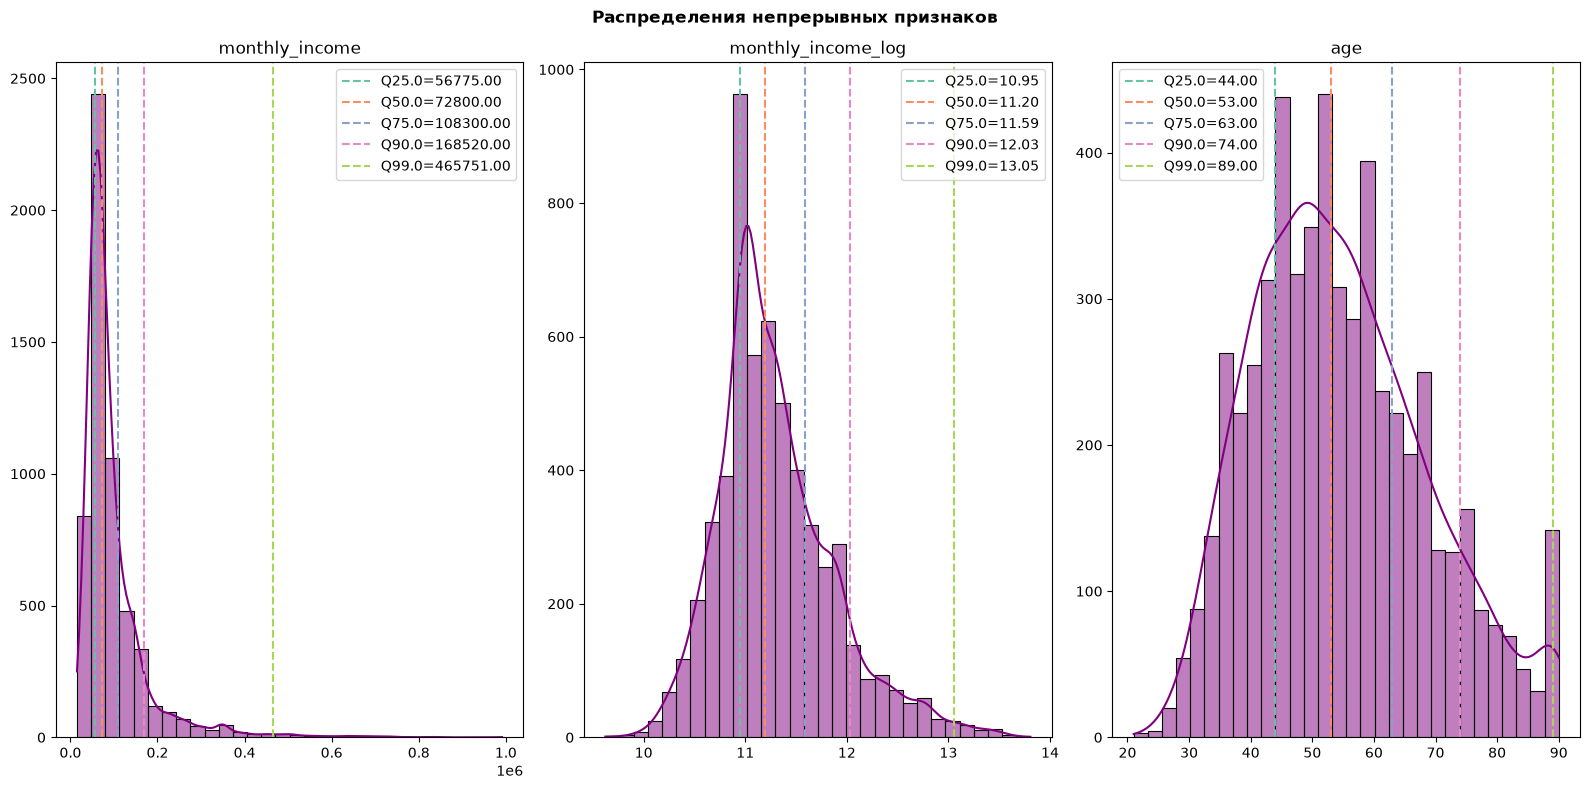

In [434]:
NUMERIC_COLS_CLIENTS = ["monthly_income", "monthly_income_log", "age"]
fig, axes = plt.subplots(1, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS_CLIENTS):
    quantiles = clients_final[col].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
    palette = sns.color_palette('Set2', n_colors=len(quantiles))
    sns.histplot(
        clients_final[col], bins=30, kde=True, 
        ax=ax, color="purple"
    )
    for (q, value), color in zip(quantiles.items(), palette):
        ax.axvline(
            value, 
            linestyle="--",
            label = f"Q{q*100}={value:.2f}",
            color=color
        )
    ax.set_title(f"{col}")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend()
fig.suptitle("Распределения непрерывных признаков", fontweight="bold")

plt.tight_layout()
plt.show()

**Transactions**

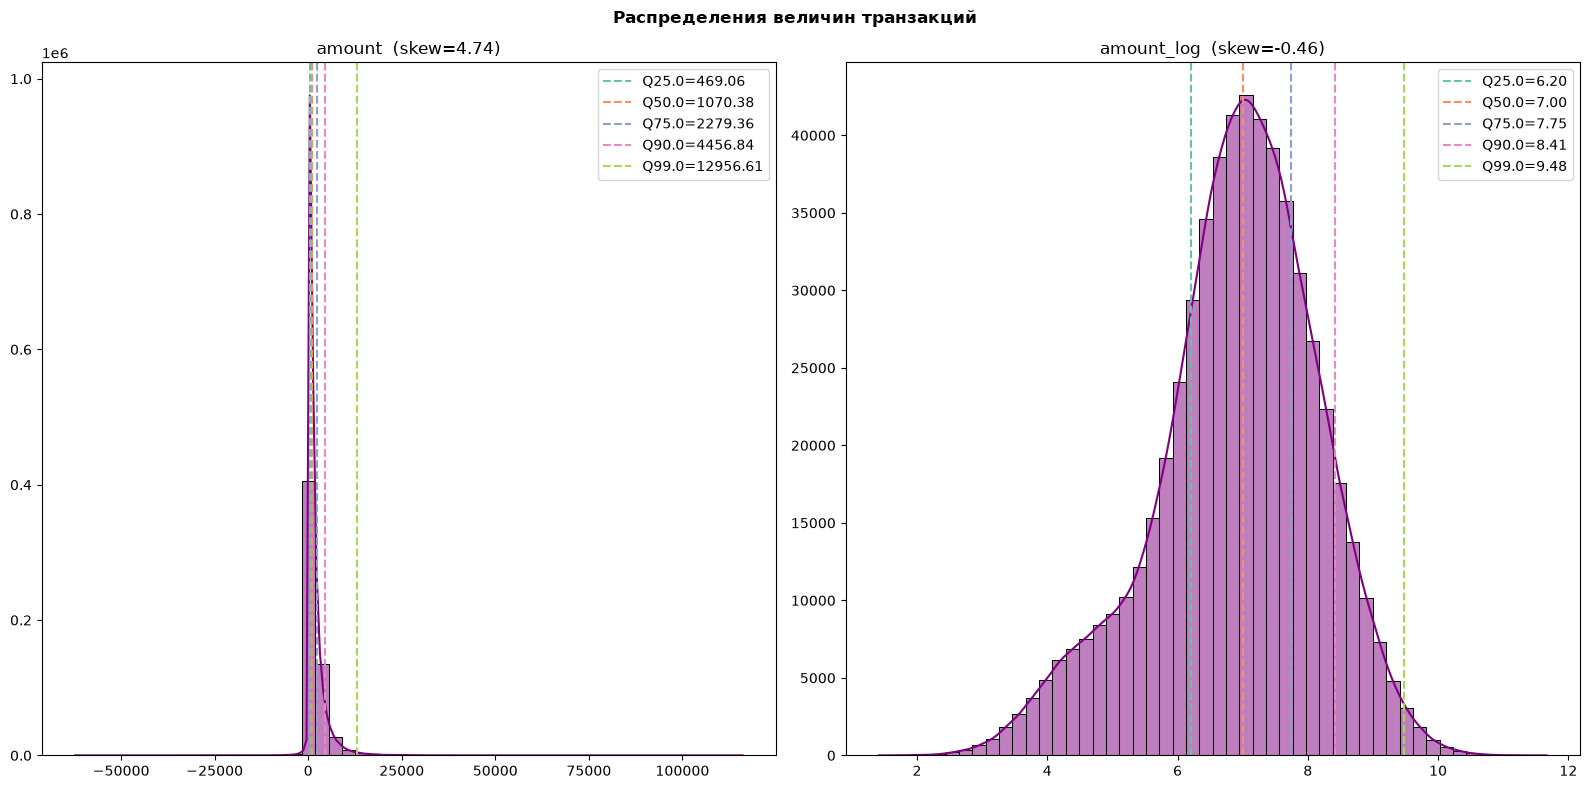

In [435]:
NUMERIC_COLS_TXN = ["amount", "amount_log"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS_TXN):
    quantiles = transactions_final[col].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
    palette = sns.color_palette('Set2', n_colors=len(quantiles))
    sns.histplot(
        transactions_final[col], bins=50, kde=True, 
        ax=ax, color="purple"
    )
    for (q, value), color in zip(quantiles.items(), palette):
        ax.axvline(
            value, 
            linestyle="--",
            label = f"Q{q*100}={value:.2f}",
            color=color
        )
    ax.set_title(f"{col}  (skew={transactions_final[col].skew():.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend()
fig.suptitle("Распределения величин транзакций", fontweight="bold")
plt.tight_layout()
plt.show()

### 5.2. Частотные характеристики категориальных признаков

**Clients**

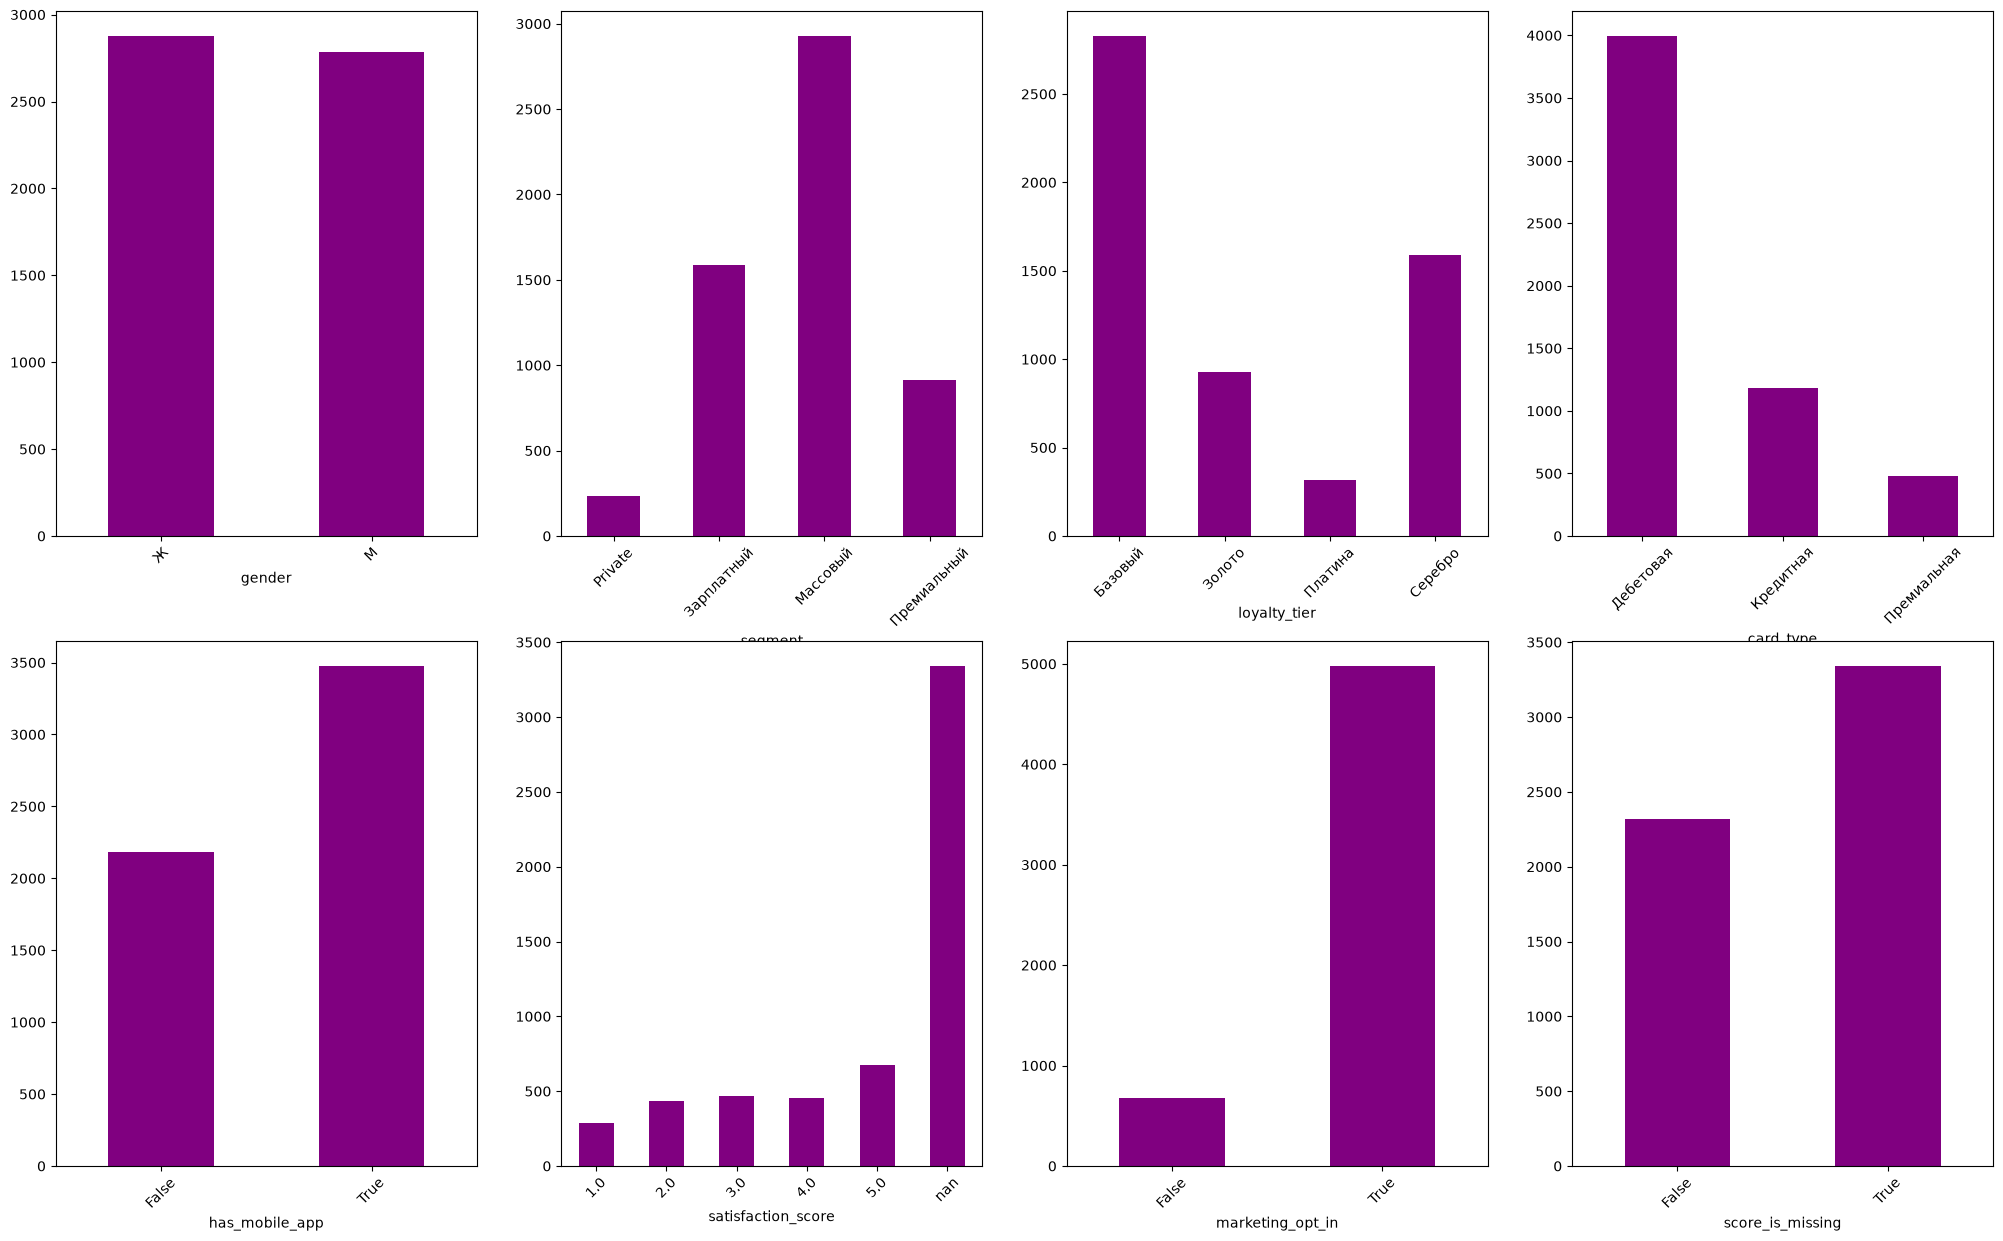

In [437]:
# графики
CATEGORICAL_COLS_CLIENTS = clients_final.select_dtypes(include=["category", "bool", "boolean"]).columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(25, 15))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS_CLIENTS):
    clients_final[col].value_counts(dropna=False).sort_index().plot.bar(ax=ax, color='purple')
    ax.tick_params(axis='x', rotation=45)
plt.show()

In [438]:
# частотные характеристики
clients_final[CATEGORICAL_COLS_CLIENTS].describe().T

,count,unique,top,freq
gender,5660,2,Ж,2877
segment,5660,4,Массовый,2928
loyalty_tier,5660,4,Базовый,2828
card_type,5660,3,Дебетовая,3995
has_mobile_app,5660,2,True,3476
satisfaction_score,2319.0,5.0,5.0,673.0
marketing_opt_in,5660,2,True,4979
score_is_missing,5660,2,True,3341


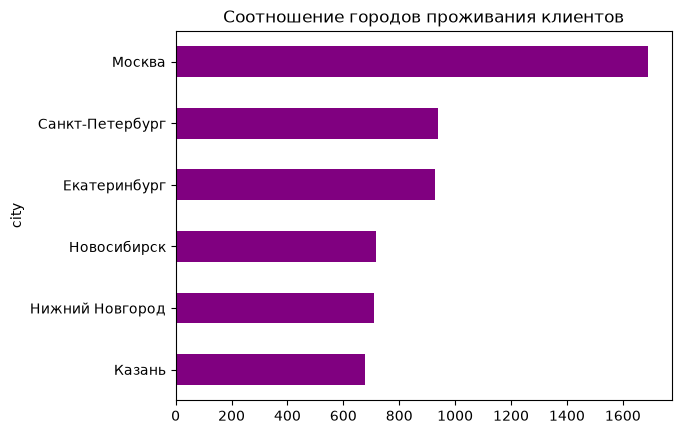

In [439]:
# отдельно посмотрим города
clients_final["city"].value_counts().plot.barh(title="Соотношение городов проживания клиентов",
                                               color="purple").invert_yaxis()
plt.show()

**Transactions**

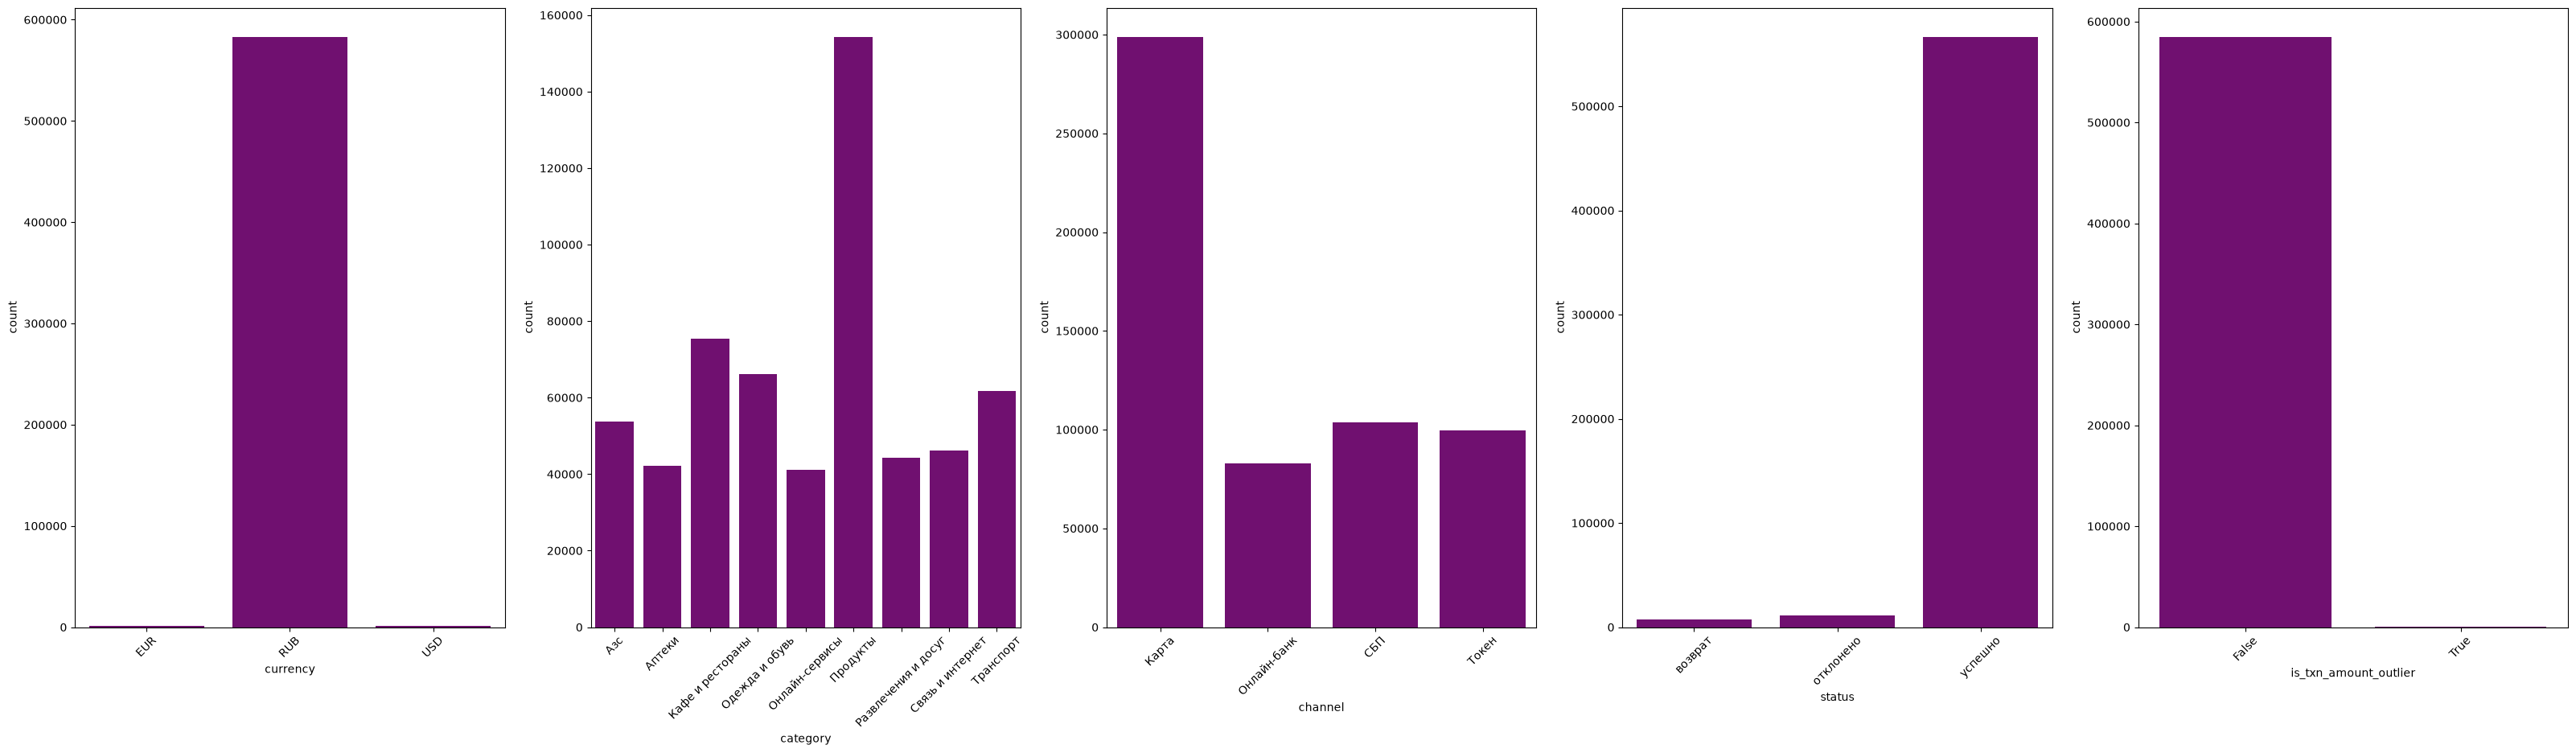

In [440]:
# графики
CATEGORICAL_COLS_TXN = transactions_final.select_dtypes(include=["category", "bool", "boolean"]).columns.tolist()
fig, axes = plt.subplots(1, 5, figsize=(40, 10))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS_TXN):
    sns.barplot(transactions_final[col].value_counts(dropna=False), 
                ax=ax,
                color="purple")
    ax.tick_params(axis='x', rotation=45)

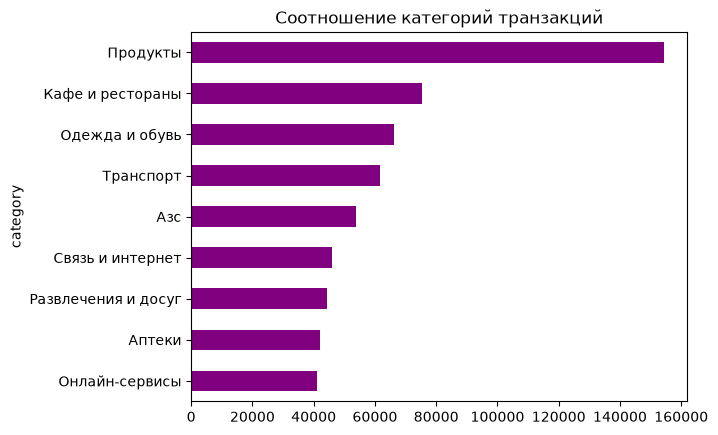

In [441]:
# отдельно посмотрим категории покупки
transactions_final["category"].value_counts().plot.barh(title="Соотношение категорий транзакций",
                                               color="purple").invert_yaxis()
plt.show()

In [442]:
transactions_final[CATEGORICAL_COLS_TXN].describe().T

,count,unique,top,freq
currency,585067,3,RUB,582711
category,585067,9,Продукты,154224
channel,585067,4,Карта,298693
status,585067,3,успешно,566354
is_txn_amount_outlier,585067,2,False,584480


### 5.3. Динамика по месяцам

In [443]:
# функция для конверсии валют
def convert_to_rub(row):
    rates = {
        "USD": 96.5,
        "EUR": 101.5,
        "RUB": 1.0,
    }
    amount = row["amount"]
    currency = row["currency"]
    rate = rates.get(currency)
    if rate is not None:
        return amount * rate
    else:
        return None

full_table["amount_rub"] = full_table.apply(convert_to_rub, axis=1)
full_table.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,amount_log,is_txn_amount_outlier,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log,amount_rub
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,6.250458,False,1948-11-27,Ж,Москва,Зарплатный,Базовый,Дебетовая,2023-07-23,2023-10-20,Зарплата в нашем банке,46600.0,False,NaT,NaN,786,True,True,10.749356,518.25
1,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,7.508875,False,1963-03-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2019-07-10,2022-03-31,Зарплата в нашем банке,65200.0,True,2024-06-01,NaN,117,True,True,11.085215,1824.16
2,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,7.313774,False,2000-06-08,Ж,Москва,Премиальный,Платина,Дебетовая,2016-08-18,2018-07-10,Не указан,74800.0,True,2024-09-01,NaN,553,True,True,11.222573,1500.83
3,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,7.914837,False,1980-10-15,Ж,Москва,Массовый,Базовый,Дебетовая,2018-11-21,2020-05-15,Не указан,58800.0,True,2025-02-01,NaN,490,True,True,10.981897,2737.60
4,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,5.538318,False,1977-11-30,М,Новосибирск,Зарплатный,Базовый,Дебетовая,2019-03-28,2022-07-22,Зарплата в нашем банке,96500.0,True,2024-03-01,NaN,329,True,True,11.477298,254.25


In [444]:
full_table.shape

(585067, 29)

Text(0.5, 1.0, 'Динамика кол-ва транзакций по месяцам')

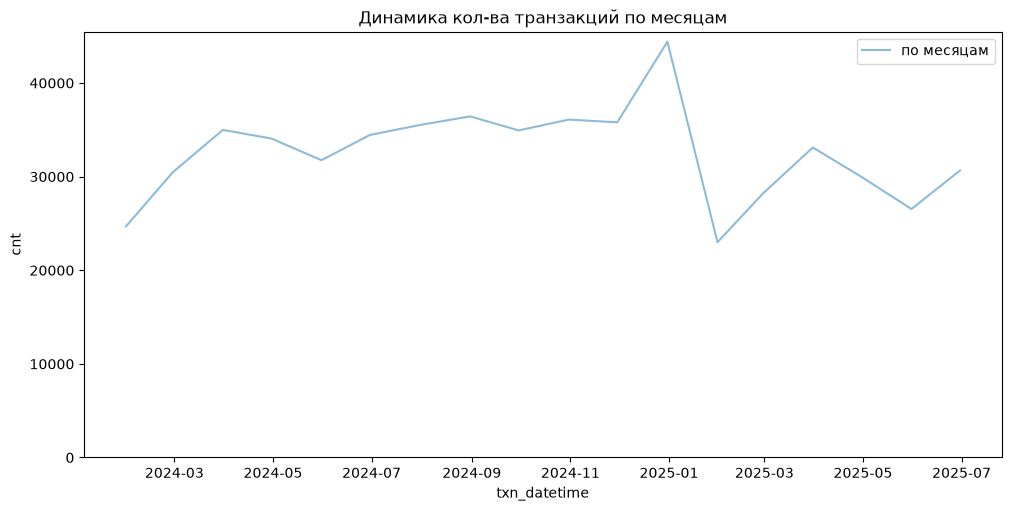

In [445]:
# 1. общая динамика по всему периоду
monthly = (full_table.set_index("txn_datetime")["amount_rub"]
          .resample("ME").agg(["sum", "count"])
          .rename(columns={"sum": "total", "count": "cnt"})
          .reset_index())

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.lineplot(data=monthly, x = "txn_datetime", y="cnt", ax=ax,  alpha=0.5, label="по месяцам")

ax.set_ylim(0, None)
ax.set_title("Динамика кол-ва транзакций по месяцам")

Сравним одинаковые периоды месяцев (январь - июнь) для базового и оцениваемого периодов, чтобы понять сезонность

Text(0.5, 1.0, 'Сравнение кол-ва транзакций за 2024 и 2025 года')

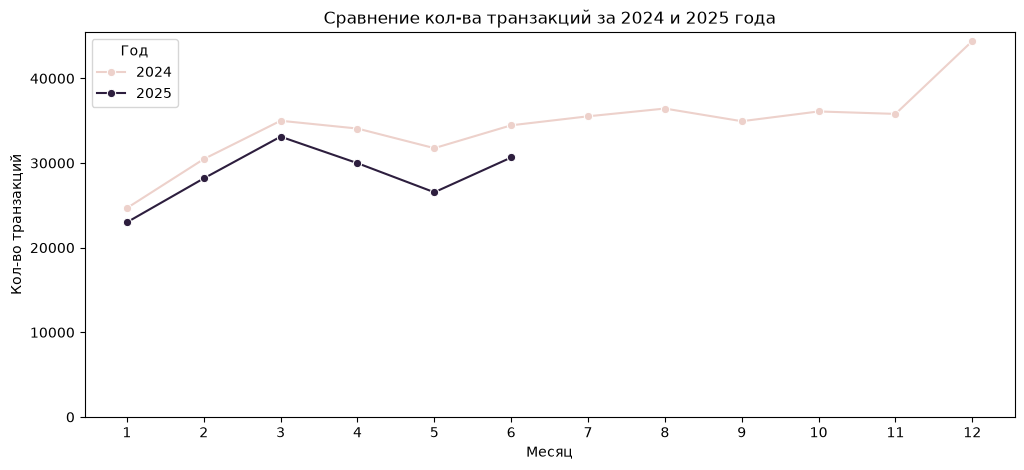

In [169]:
monthly["year"] = monthly.set_index("txn_datetime").index.year
monthly["month"] = monthly.set_index("txn_datetime").index.month

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="month", y="cnt", hue="year", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Месяц")
ax.set_ylabel("Кол-во транзакций")
ax.legend(title="Год")
ax.set_ylim(0, None)
ax.set_title("Сравнение кол-ва транзакций за 2024 и 2025 года")

Посмотрим динамику для успешных транзакций со способом оплаты "карта", т.к. в описании задачи сказано, что проблема заключается в том, что клиенты стали реже пользоваться именно картами. Рассматриваем только успешные транзакции, т.к. именно они создают нужную активность, а не возвраты/отклонённые транзакции.

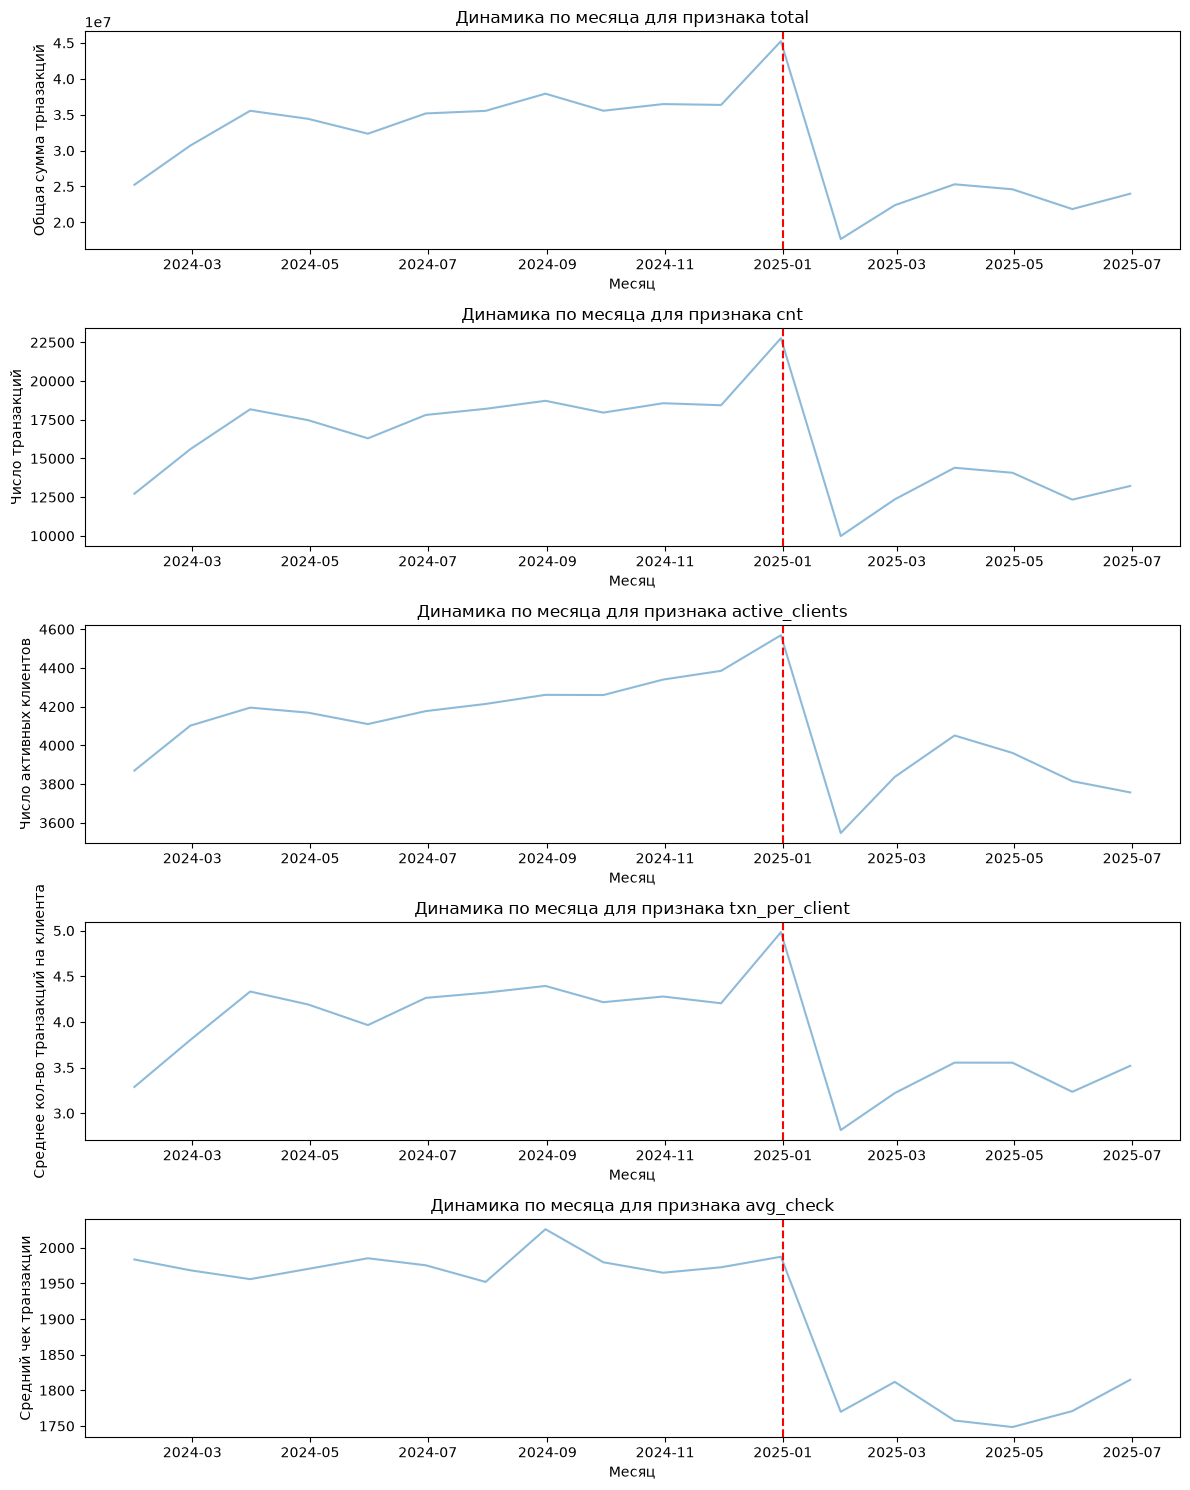

In [446]:
valid_transactions = full_table[(full_table['channel'] == "Карта") & (full_table["status"] == "успешно") & (full_table["amount_rub"] > 0)].copy()
monthly_valid = (valid_transactions.set_index("txn_datetime")
          .resample("ME")
          .agg(
              total=("amount_rub", "sum"),
              cnt=("amount_rub", "count"),
              active_clients=("client_id", 'nunique')
          ).reset_index())

monthly_valid["year"] = monthly_valid.set_index("txn_datetime").index.year
monthly_valid["month"] = monthly_valid.set_index("txn_datetime").index.month
monthly_valid["txn_per_client"] = monthly_valid["cnt"]/monthly_valid["active_clients"]
monthly_valid["avg_check"] = monthly_valid["total"]/monthly_valid["cnt"]

cols = ["total", "cnt", "active_clients", "txn_per_client", "avg_check"]
labels = {
    "total": "Общая сумма трназакций", 
    "cnt": "Число транзакций", 
    "active_clients": "Число активных клиентов",
    "txn_per_client": "Среднее кол-во транзакций на клиента",
    "avg_check": "Средний чек транзакции"
}
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 15))
for ax, col in zip(axes, cols):
    sns.lineplot(data=monthly_valid, x = "txn_datetime", y=col, ax=ax,  alpha=0.5)
    ax.axvline(pd.Timestamp('2025-01-01'), color='red', ls='--')
    ax.set_title(f"Динамика по месяца для признака {col}")
    ax.set_xlabel("Месяц")
    ax.set_ylabel(labels[col])
plt.tight_layout()

Динамика на выбранных транзакциях за один и тот же период в 2024 и 2025 годах

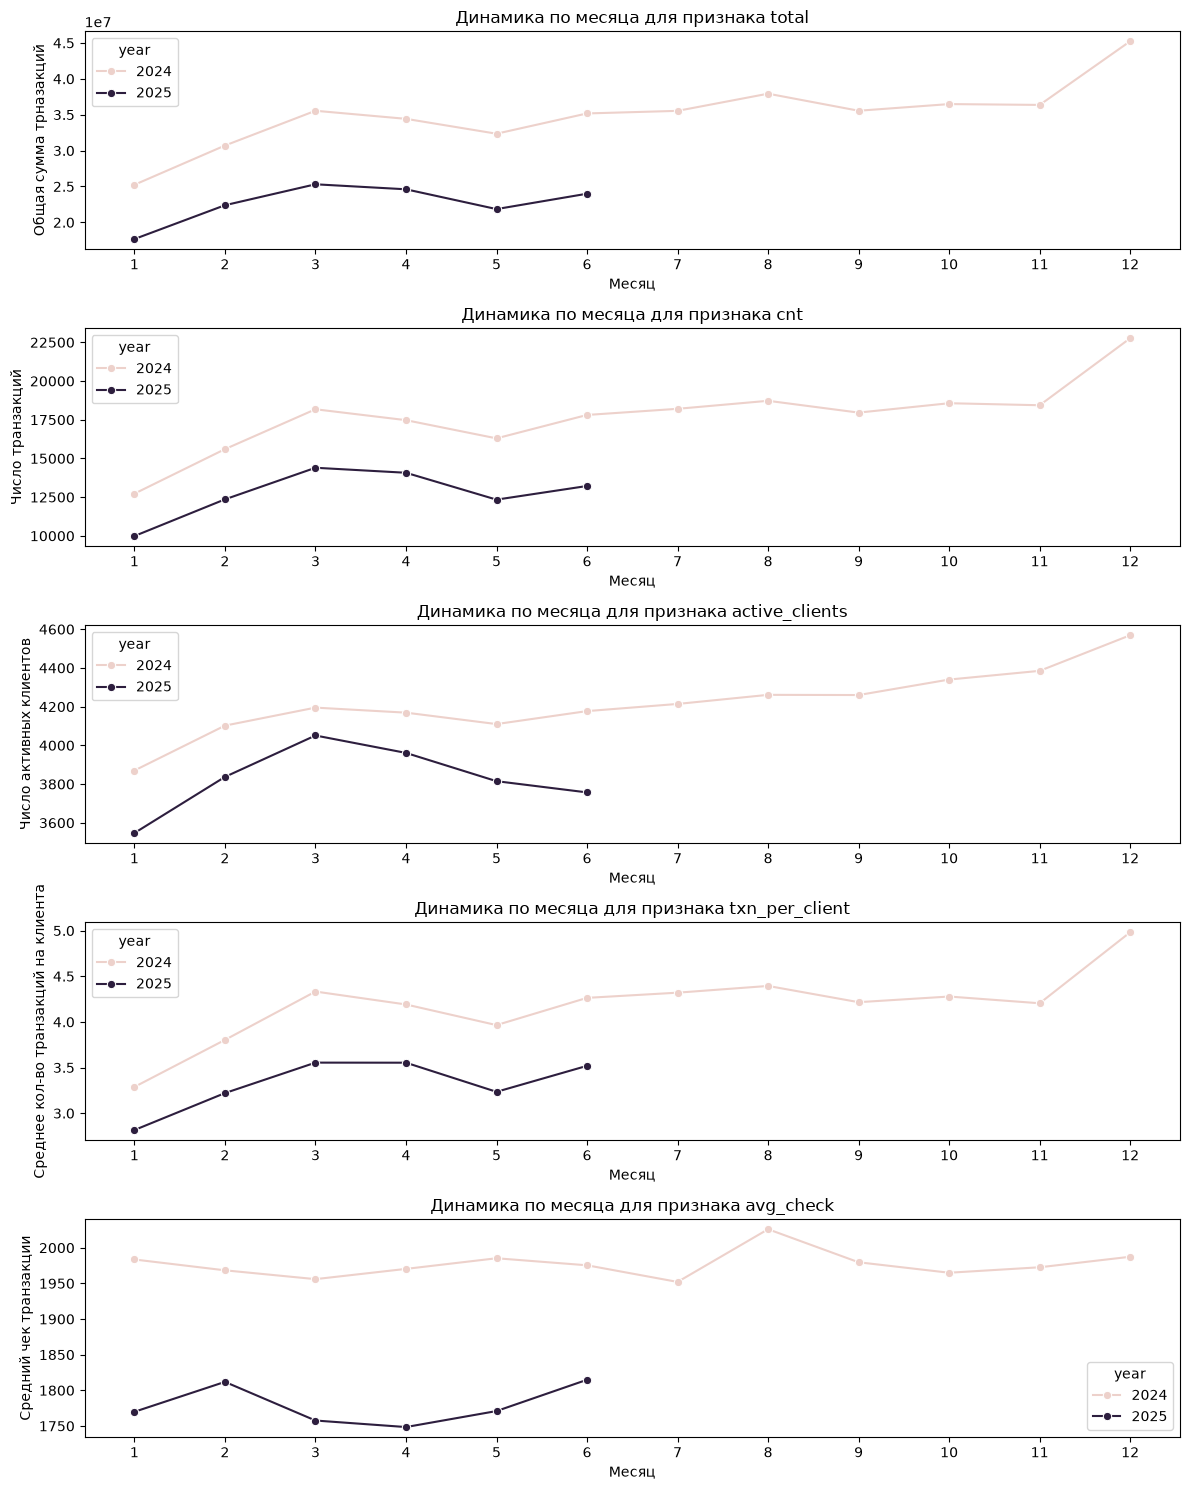

In [447]:
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 15))
for ax, col in zip(axes, cols):
    sns.lineplot(data=monthly_valid, x="month", y=col, hue="year", marker="o", ax=ax)
    ax.set_xticks(range(1, 13))
    ax.set_title(f"Динамика по месяца для признака {col}")
    ax.set_xlabel("Месяц")
    ax.set_ylabel(labels[col])
plt.tight_layout()

Вывод: формы кривых за 2024 и 2025 год для числа транзакций за месяц и общей суммы примерно совпадают: рост кривой к марту, затем падение к маю, потом снова начало роста. Можно предположить, что есть сезонность.
Но для количества активных клиентов не так: если за 2024 год после мая кривая снова начинает расти, то в 2025 она продолжает снижаться. Поэтому можно предположить, что снижение активности характеризуется именно оттоком части клиентов, а не уменьшением кол-ва транзакций.

### 5.4. Разрезы и связи между признаками

**Связи между признаками клиентов**

In [448]:
clients_final.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log,age
0,C004755,1972-02-03,Ж,Москва,Премиальный,Серебро,Кредитная,2020-11-19,2022-04-03,Не указан,148050.0,True,2024-08-01,NaN,805,True,True,11.905305,54
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,2012-06-16,2017-08-31,Зарплата в нашем банке,61600.0,True,2025-05-01,NaN,256,True,True,11.028417,50
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,2019-07-10,2021-11-03,Зарплата в нашем банке,102900.0,False,NaT,NaN,198,True,True,11.541513,64
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,2024-10-13,2025-02-08,Зарплата в нашем банке,85100.0,True,2024-04-01,NaN,927,True,True,11.351582,48
4,C004093,1992-10-13,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,2015-08-27,2017-09-24,Зарплата в нашем банке,47900.0,True,2024-03-01,NaN,171,True,True,10.776871,34


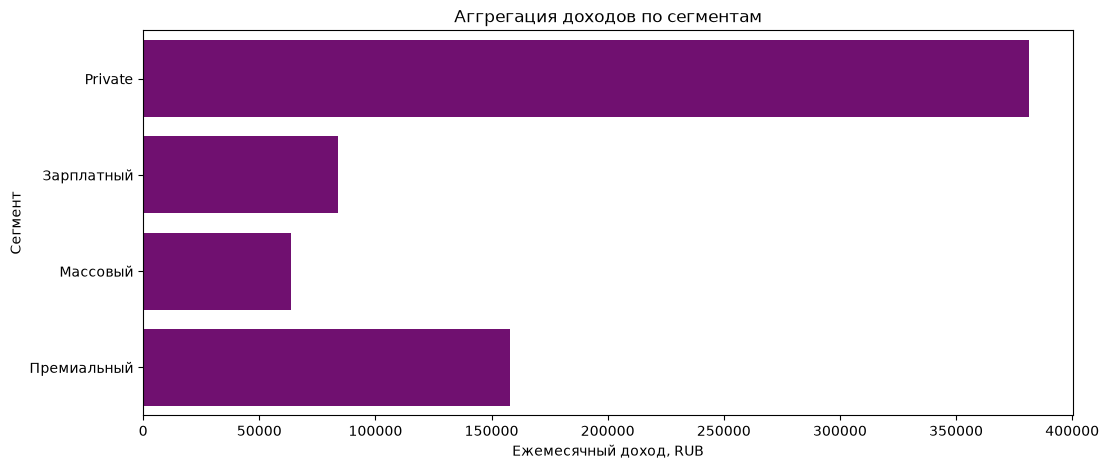

In [449]:
# сегмент - доход
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=clients_final, x='monthly_income', y='segment', color='purple', errorbar=None,)
plt.title("Аггрегация доходов по сегментам")
plt.xlabel("Ежемесячный доход, RUB")
plt.ylabel("Сегмент")
plt.show()

Text(0, 0.5, 'Доля')

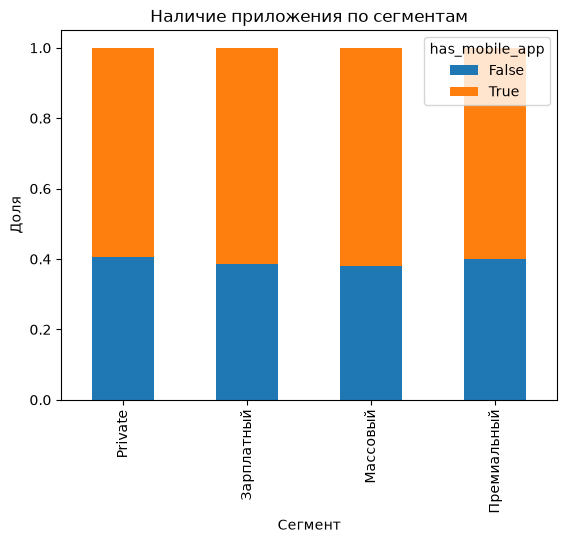

In [450]:
# сегмент - приложение
ct = pd.crosstab(clients_final["segment"], clients_final["has_mobile_app"])
ct.div(ct.sum(axis=1), axis=0).plot(kind="bar", stacked=True)
plt.title("Наличие приложения по сегментам")
plt.xlabel("Сегмент")
plt.ylabel("Доля")

Text(0, 0.5, 'Кол-во клиентов')

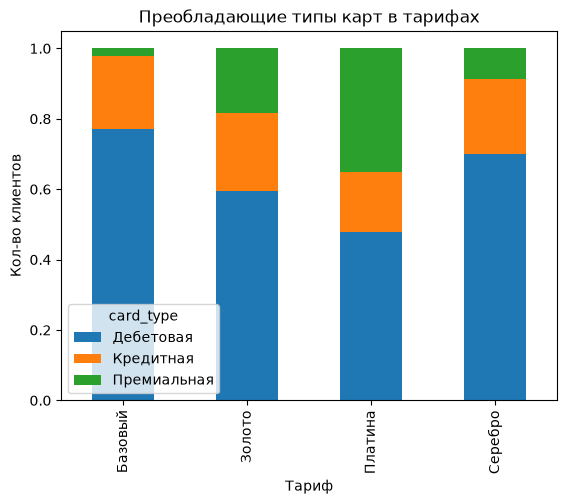

In [158]:
# тариф - тип карты
ct = pd.crosstab(clients_final["loyalty_tier"], clients_final["card_type"])
ct.div(ct.sum(axis=1), axis=0).plot(kind="bar", stacked=True)
plt.title("Преобладающие типы карт в тарифах")
plt.xlabel("Тариф")
plt.ylabel("Доля")

**Связи между признаками транзакций**

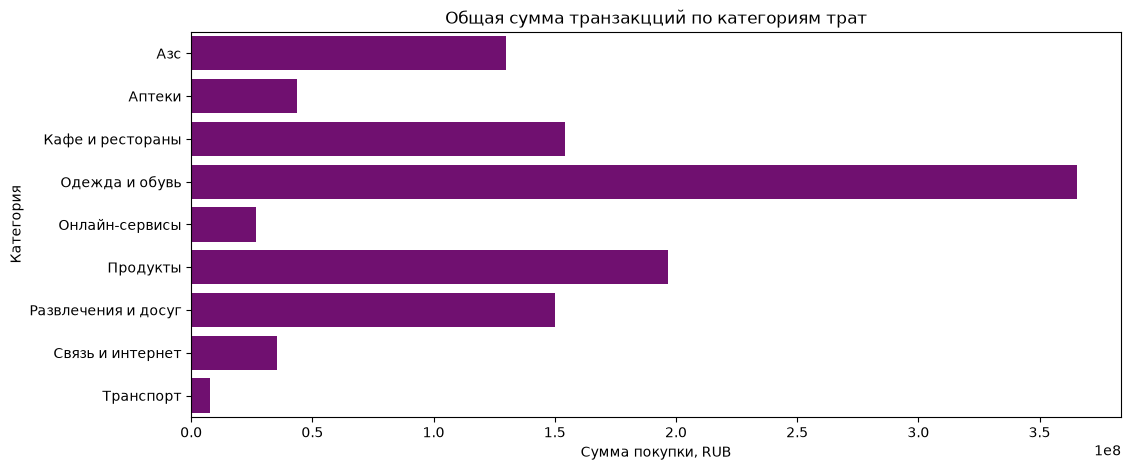

In [182]:
# категория - сумма
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=full_table, x='amount_rub', y='category', color='purple', estimator=np.sum, errorbar=None)
plt.title("Общая сумма транзакцций по категориям трат")
plt.xlabel("Сумма покупки, RUB")
plt.ylabel("Категория")
plt.show()

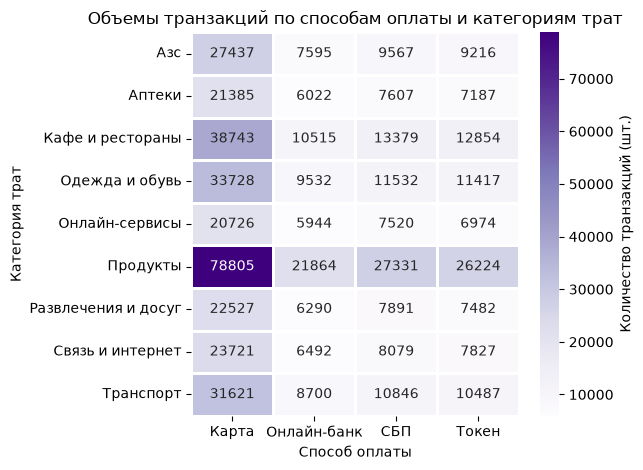

In [185]:
# категория - способ оплаты
cnt = full_table.pivot_table(index="category", columns="channel", values="txn_id", aggfunc="count")
sns.heatmap(cnt,
            annot=True,
            fmt="d",
            cmap="Purples",
            linewidths=0.8, 
            linecolor="white",
            cbar_kws={"label": "Количество транзакций (шт.)"}, 
)
plt.title("Объемы транзакций по способам оплаты и категориям трат")
plt.xlabel("Способ оплаты")
plt.ylabel("Категория трат")
plt.tight_layout()
plt.show()

Отметим, что клиенты преимущественно используют карту во всех категориях

**Связь признаков клиентов с признаками транзакций**

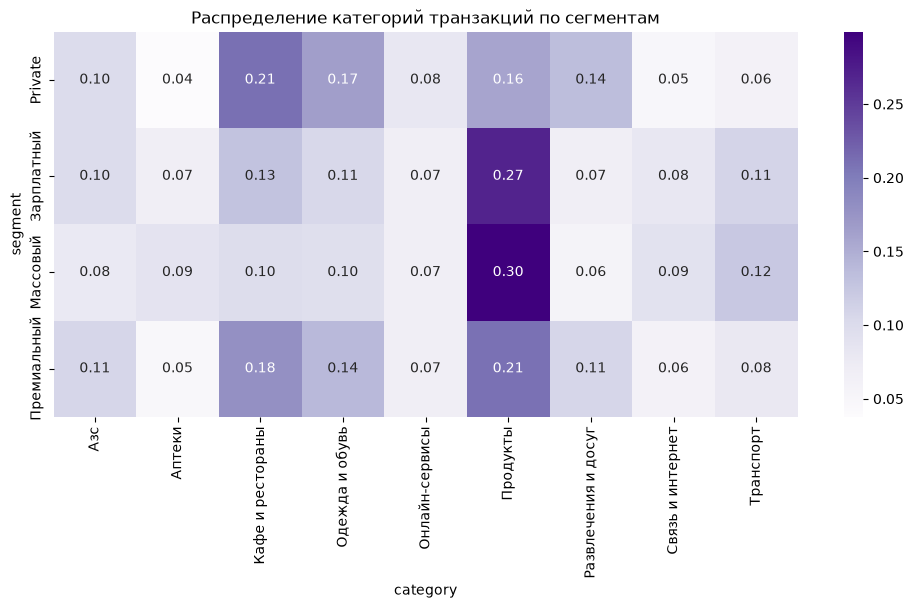

In [187]:
# категории трат по сегментам
segment_category = pd.crosstab(valid_transactions["segment"], valid_transactions["category"], normalize="index")
plt.figure(figsize=(12, 5))
sns.heatmap(
    segment_category,
    annot=True,
    fmt=".2f",
    cmap="Purples"
)
plt.title("Распределение категорий транзакций по сегментам")
plt.show()

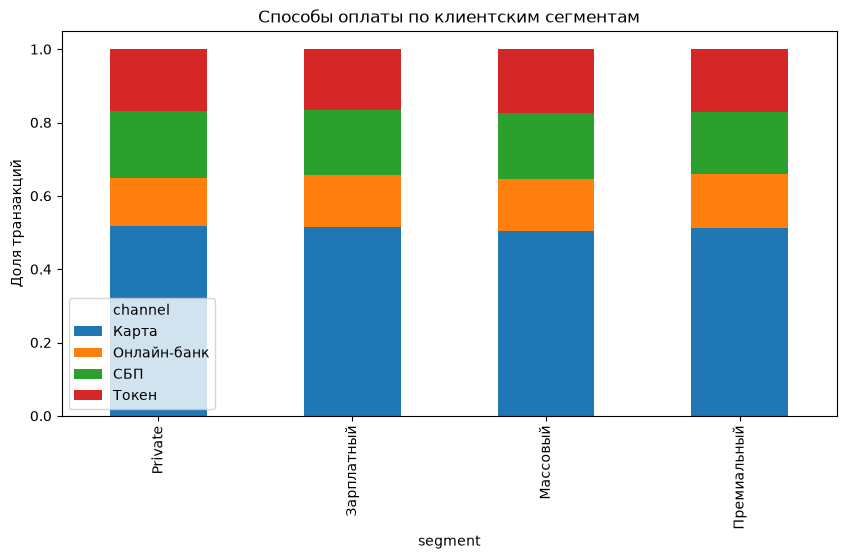

In [194]:
# сегмент клиента - способ оплаты
segment_payment = pd.crosstab(full_table["segment"], full_table["channel"], normalize="index")
segment_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Способы оплаты по клиентским сегментам")
plt.ylabel("Доля транзакций")
plt.show()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

В качестве метрики активности выбираю количество успешных транзакций, совершённых клиентом за месяц с типом оплаты "карта", т.к. нас интересует именно факт того, почему стали меньше пользоваться картами. Считать будем на клиентах, открывших карту раньше января 2024 года, т.к. если карта была открыта позже, то метрика по месяцам до её открытия будет = 0 не из-за того, что человек не активен, а прсто потому что карта ещё не открыта. Чтобы избежать того, чтобы ошибочно посчитать такие случаи как неактивность, выделяем тех, у кого карта открыта не позже января 2024 года.

Метрика не увидит снижение сумм транзакций: если само их кол-во останется примерно таким же, но изменятся суммы, активность от этого не поменяется.

In [481]:
# сделаем помесячную сводную таблицу для каждого клиента
vt = valid_transactions.copy()
vt["month"] = vt["txn_datetime"].dt.to_period("M").dt.to_timestamp()
months = pd.date_range("2024-01-01", "2025-06-01", freq="MS")
all_clients = clients_final["client_id"].unique()

pivot = (
    vt.groupby(["client_id", "month"]).size()
    .unstack("month", fill_value=0)
    .reindex(index=all_clients, columns=months, fill_value=0)
)
pivot

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
client_id,,,,,,,,,,,,,,,,,,
C004755,3,5,5,1,3,1,5,2,2,5,3,3,0,0,0,0,0,0
C004627,8,10,6,8,13,12,15,17,7,13,7,11,1,2,0,0,0,0
C001846,4,3,3,2,7,7,9,5,7,3,6,5,2,3,1,2,3,4
C004355,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1
C004093,2,0,1,6,8,6,9,7,6,1,1,2,0,1,1,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
C000756,3,4,1,0,1,0,1,3,1,3,1,0,0,0,1,0,0,0
C002224,2,8,6,5,5,7,7,1,13,9,9,9,1,1,0,0,0,0
C002374,0,0,0,0,0,0,0,0,0,0,1,2,0,1,1,1,1,1


In [482]:
cohort_ids = clients_clean.loc[clients_clean["card_open_date"] < "2024-01-01", "client_id"]

Определим, что именно является снижением активности - будем сравнивать одинаковые месяца за 2024 и 2025 года

In [483]:
h24, h25 = months[:6], months[12:]

clients_stats = pd.DataFrame({
    "n24": pivot.loc[cohort_ids, h24].sum(axis=1),
    "n25": pivot.loc[cohort_ids, h25].sum(axis=1),
})
clients_stats["avg24"], clients_stats["avg25"] = clients_stats["n24"] / 6, clients_stats["n25"] / 6
clients_stats["delta_pct"] = clients_stats["avg25"] / clients_stats["avg24"].where(clients_stats["avg24"] > 0) - 1
clients_stats

,n24,n25,avg24,avg25,delta_pct
client_id,,,,,
C004755,18,0,3.000000,0.000000,-1.000000
C004627,57,3,9.500000,0.500000,-0.947368
C001846,26,15,4.333333,2.500000,-0.423077
C004093,23,4,3.833333,0.666667,-0.826087
C005358,31,66,5.166667,11.000000,1.129032
...,...,...,...,...,...
C005196,39,17,6.500000,2.833333,-0.564103
C000756,9,1,1.500000,0.166667,-0.888889
C002224,33,2,5.500000,0.333333,-0.939394


Посмотрим, как меняется активность за базовый период - по полугодиям в 2024 году(т.е. в период, когда активного спада не наблюдалось). Исходя из этого сделаем вывод, какие пороги выбрать для отслеживания снижения в 2025 году. Возможно, большинство клиентов вообще перестали пользоваться картами.

In [484]:
# посмотрим, как меняется активность за полугодия в 2024 году(т.е. в период, когда активного спада не наблюдалось)
a = pivot.loc[cohort_ids]
f1 = a[months[:6]].sum(axis=1)
f2 = a[months[6:12]].sum(axis=1)

base = clients_stats.index[clients_stats["n24"] >= 6]             
ratio_all = f2[base].sum() / f1[base].sum() 
noise = (f2[base] / f1[base].where(f1[base] > 0)) / ratio_all - 1

print(noise.quantile([0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.9]).round(3))

0.01   -0.637
0.05   -0.452
0.10   -0.360
0.25   -0.200
0.50   -0.008
0.75    0.209
0.90    0.468
dtype: float64


Выбираем порог так, чтобы он выходил за пределы снижения в "нормальное время", т.к. иначе это бы не отметилось как видимое падение активности. 

Задаём два порога:
- умеренное снижение активность (порог для разницы активностей за первое полугодие 2024 и 2025 годов: -0.45)
- сильное снижение активности (порог для разницы активностей за первое полугодие 2024 и 2025 годов: -0.7)

И разделим активных в рассматриваемый период времени клиентов на группы по характеру изменения активности:
1. перестал пользоваться картой вообще: метрика = 0 за полугодие 2025 года
2. клиент с редкими покупками: малое транзакций за рассматриваемое полугодие 2024 года
3. клиент с умеренным снижением: посчитанная разница между `n25` и `n24` <= T_mod
4. клиент с умеренным снижением: посчитанная разница между `n25` и `n24` <= T_strong
5. стабильный клиент: посчитанная разница между `n25` и `n24` <= 0.3

In [485]:
T_mod, T_strong = -0.45, -0.7
active_clients = clients_stats[clients_stats["n24"] > 0].copy()
active_clients["status"] = np.select(
    [
        active_clients["n25"] == 0,
        active_clients["n24"] < 6,
        active_clients["delta_pct"] <= T_strong,
        active_clients["delta_pct"] <= T_mod,
        active_clients["delta_pct"] < 0.3
    ],
    [
        "ушёл",
        "редкий",
        "сильное снижение",
        "умеренное снижение",
        "стабильный"
    ],
    default="рост"
)

In [486]:
res = active_clients.groupby("status").agg(clients=("n24", "size"), n24=("n24", "sum"), n25=("n25", "sum")) # n24, n25 - кол-во транзакций за полугодия у всех клиентов
res["share_clients"] = res["clients"] / res["clients"].sum() # доля клиентов с таким статусом активности
res["delta"] = res["n25"] - res["n24"] # общая разница кол-ва транзакций
res["share_of_total_drop"] = res["delta"] / (active_clients["n25"].sum() - active_clients["n24"].sum()) # какую доля от всего паедения составляет падение этого статуса
print(res.round(3))

                    clients    n24    n25  share_clients  delta  share_of_total_drop
status                                                                              
редкий                  491   1520   1864          0.103    344               -0.013
рост                    648  12808  20722          0.136   7914               -0.303
сильное снижение        816  22497   3071          0.171 -19426                0.744
стабильный             1886  43618  39669          0.396  -3949                0.151
умеренное снижение      734  15888   6646          0.154  -9242                0.354
ушёл                    186   1748      0          0.039  -1748                0.067


Можно заметить, что основной вклад в сокращение кол-ва транзакций внесли клиенты, сильно сократившие частоты использования карт, а не те, кто полностью перестал ими пользоваться. На группу с "сильным снижением" приходится около 74% общего сокращения кол-ва транзакций.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

После определения статусов активности для каждого клиента перейдём к формированию групп по признакам клиентов. Посмотрим динамику клиентов каждого статуса из трёх, означающих снижение активности(сильное снижение, умеренное снижение, ушёл) за 2025 год, чтобы примерно представлять, какие тенденции у них в поведении к концу оцениваемого периода.

In [487]:
# рассматриваем всех, у кого есть снижение
declined = active_clients[active_clients["status"].isin(["ушёл", "сильное снижение", "умеренное снижение"])].copy()

# траектория внутри 2025: янв-мар против апр-июн
q1 = pivot.loc[declined.index, months[12:15]].sum(axis=1)
q2 = pivot.loc[declined.index, months[15:18]].sum(axis=1)
declined["q1_25"], declined["q2_25"] = q1, q2
declined["trajectory"] = np.select(
    [(q1 == 0) & (q2 == 0),
     q2 <= 0.5 * q1,
     q2 >= 1.5 * q1],
    ["нет покупок", "затухание к концу периода", "восстановление"],
    default="стабильно низкий уровень",
)

print(declined.groupby("status")["trajectory"].value_counts(normalize=True).round(3))

status              trajectory               
сильное снижение    затухание к концу периода    0.442
                    восстановление               0.330
                    стабильно низкий уровень     0.228
умеренное снижение  стабильно низкий уровень     0.399
                    затухание к концу периода    0.341
                    восстановление               0.260
ушёл                нет покупок                  1.000
Name: proportion, dtype: float64


Начинаем смотреть, по каким признакам будем объединять клиентов в группы. Логично, что в одной группе должны быть клиенты с одинаковым статусом изменения активности, чтобы к ним можно было потом применять один и тот же механизм по возврату активности. Посмотрим, какой характер активности преобладает для каждой категории.

In [488]:
client_info = clients_final.set_index("client_id")
analysis_df = active_clients[active_clients["n24"] >= 6].join(client_info) # сразу не рассматриваем клиентов с маленьким кол-вом транзакций ещё в 2024
analysis_df["age"] = 2026 - analysis_df["birth_date"].dt.year
# создадим категории по возрастам и по доходам
analysis_df["age_group"] = pd.cut(
    analysis_df["age"],
    bins=[18, 31, 46, 60, 100],
    labels = ["18-30", "31-45", "46-59", "60+"],
    right=False
)
analysis_df["income_group"] = pd.qcut(
    analysis_df["monthly_income"],
    q=4, 
    labels=["Низкий", "Средний", "Выше среднего", "Высокий"]
)

In [489]:
cats = ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "age_group", "income_group", "satisfaction_score"]
order = ["ушёл", "сильное снижение", "умеренное снижение", "стабильный", "рост"]
for col in cats:
    t = pd.crosstab(analysis_df[col], analysis_df["status"], normalize="index").round(3)   # состав внутри каждого статуса
    print(f"\n=== {col} ===")
    print(t)


=== segment ===
status        рост  сильное снижение  стабильный  умеренное снижение   ушёл
segment                                                                    
Private      0.199             0.118       0.547               0.112  0.025
Зарплатный   0.230             0.143       0.523               0.091  0.012
Массовый     0.108             0.241       0.382               0.240  0.029
Премиальный  0.170             0.153       0.536               0.127  0.014

=== loyalty_tier ===
status         рост  сильное снижение  стабильный  умеренное снижение   ушёл
loyalty_tier                                                                
Базовый       0.134             0.213       0.425               0.200  0.028
Золото        0.192             0.160       0.497               0.136  0.015
Платина       0.189             0.108       0.545               0.140  0.018
Серебро       0.167             0.201       0.456               0.162  0.015

=== card_type ===
status        рост  силь

Наблюдения:
- Почти половина клиентов Массового сегмента имеет снижение, а доля стабильных всего ~38%
- Доля клиентов с сильным снижением заметно выше в массовом сегменте, чем в остальных
- Чем выше уровень лояльности, тем ниже доля клиентов с сильным снижением
- Среди клиенты возрастной группы 18-30 около 36% имеют сильное снижение - это выше остальных возрастных групп, следущая за ними возрастная группа - 31-45
- Среди клиентов с мобильным приложением чаще наблюдается резкое снижение активности, а у клиентов без - умеренное снижение
- Есть тенденция по доходу: чем выше доход, тем ниже доля сильного снижения

**Гипотезы:**
- Массовый сегмент может являться одним из хорошим признаком для отбора в группы
- Возрастная группа 18-31 так же может быть хорошмс кандидатом для формирорования группы
- Как наличие, так и отсутствие мобильного приложения может быть неплохим признаком
- Возможно, клиенты с низким доходом больше склонны сокращать использование карты

Проверим выделенные нами признаки и их сочетания

In [540]:
ci = analysis_df[["loyalty_tier", "card_type", "city", "age_group", "income_group", "segment", "has_mobile_app", "marketing_opt_in"]] 
d = declined.join(ci)
app = d["has_mobile_app"].eq(True)
candidates = {
    "Возраст 18–30": d["age_group"].eq("18-30"),
    "Возраст 31-45": d["age_group"].eq("31-45"),
    "Массовый сегмент": d["segment"].eq("Массовый"),
    "Низкий доход": d["income_group"].eq("Низкий"),
    "Массовый сегмент без приложения":  d["segment"].eq("Массовый") & ~app,
    "С приложением из Москвы": app & d["city"].eq("Москва"),
    "18–30 лет и массовый сегмент": d["age_group"].eq("18-30") & d["segment"].eq("Массовый"),
    "18–30 лет с приложением": d["age_group"].eq("18-30") & app,
    "31-45 лет и массовый сегмент": d["age_group"].eq("31-45") & d["segment"].eq("Массовый"),
    "31-45 лет с приложением": d["age_group"].eq("31-45") & app,
    "Низкий доход и базовая лояльность": d["income_group"].eq("Низкий") & d["loyalty_tier"].eq("Базовый")
}

rows = []
for name, mask in candidates.items():
    g = d[mask]
    rows.append({
        "group": name,
        "clients": len(g),
        "share_of_declined": len(g) / len(d),
        "exit": (g["status"] == "ушёл").mean(),
        "strong": (g["status"] == "сильное снижение").mean(),
        "moderate": (g["status"] == "умеренное снижение").mean(),
        "fade": g["trajectory"].eq("затухание к концу периода").mean(),
        "recover": g["trajectory"].eq("восстановление").mean(),
    })

candidate_stats = pd.DataFrame(rows).set_index("group")
print("Статистики для проверки гипотез:")
print(candidate_stats.round(3))

Статистики для проверки гипотез:
                                   clients  share_of_declined   exit  strong  moderate   fade  recover
group                                                                                                 
Возраст 18–30                           31              0.018  0.032   0.613     0.355  0.355    0.323
Возраст 31-45                          474              0.273  0.065   0.599     0.335  0.397    0.302
Массовый сегмент                      1119              0.645  0.056   0.474     0.470  0.379    0.278
Низкий доход                           488              0.281  0.051   0.486     0.463  0.367    0.291
Массовый сегмент без приложения        475              0.274  0.032   0.425     0.543  0.457    0.208
С приложением из Москвы                287              0.165  0.056   0.533     0.411  0.321    0.334
18–30 лет и массовый сегмент            19              0.011  0.053   0.474     0.474  0.316    0.421
18–30 лет с приложением                 

Самые вероятные кандидаты в группы:
1) клиенты возрастной группы 31-45 лет с приложением
2) клиенты массового сегмента без приложения
3) клиенты массового сгемента возрастной группы 31-45 лет - эта группа может накладываться на первые две, поэтому сначала оценим её численность, чтобы сказать, можно ли их выделить в отдельную группу

Для каждой выбранной нами группы посчитаем разницу с её дополнением, чтобы понять, действительно ли наши кандидаты отличаются от остальных клиентов со снижением 

In [541]:
rows = []
for name, mask in candidates.items():
    g = d[mask]
    other = d[~mask]

    rows.append({
        "group": name,
        "clients": len(g),
        "strong_group": g["status"].eq("сильное снижение").mean(),
        "strong_other": other["status"].eq("сильное снижение").mean(),
        "strong_diff_pp": 100 * (g["status"].eq("сильное снижение").mean() - other["status"].eq("сильное снижение").mean()),
        "moderate_diff_pp": 100 * (g["status"].eq("умеренное снижение").mean() - other["status"].eq("умеренное снижение").mean()),
        "fade_diff_pp": 100 * (g["trajectory"].eq("затухание к концу периода").mean()- other["trajectory"].eq("затухание к концу периода").mean()
        )
    })

comparison = pd.DataFrame(rows).set_index("group")
print(comparison.round(3))

                                   clients  strong_group  strong_other  strong_diff_pp  moderate_diff_pp  fade_diff_pp
group                                                                                                                 
Возраст 18–30                           31         0.613         0.467          14.545            -6.921         0.293
Возраст 31-45                          474         0.599         0.422          17.760           -12.018         6.144
Массовый сегмент                      1119         0.474         0.464           1.010            13.295         7.583
Низкий доход                           488         0.486         0.464           2.171             5.606         2.065
Массовый сегмент без приложения        475         0.425         0.487          -6.165            16.568        14.439
С приложением из Москвы                287         0.533         0.458           7.554            -1.397        -3.762
18–30 лет и массовый сегмент            19      

Проверим, насколько группы накладываются друг на друга

In [538]:
selected = [
    "31-45 лет с приложением",
    "Массовый сегмент без приложения",
    "С приложением из Москвы"
]
overlap = pd.DataFrame(
    {
        name: [
            int((candidates[name] & candidates[other]).sum())
            for other in selected
        ]
        for name in selected
    },
    index=selected
)
print(overlap)

                                 31-45 лет с приложением  Массовый сегмент без приложения  С приложением из Москвы
31-45 лет с приложением                              363                                0                      111
Массовый сегмент без приложения                        0                              475                        0
С приложением из Москвы                              111                                0                      287


На данном этапе точно оставляем группы:
- "G1: клиенты возрастной категории 31-45 лет с приложением, у которых наблюдается резкое и сильное снижение активности"
- "G2: клиенты массового сегмента без приложения, у которых наблюдается умеренное снижение активности и её затухание к концу исследуемого периода"
- "G3: клиенты из Москвы с приложением"

Группы G1 и G2 выбираем их таким образом, т.к. они не пересекаются между собой, захватывают достаточное кол-во клиентов и отражают разные виды снижения активности. Группа G3 также вообще не пересекается с G2, но имеет пересечение с G1

In [542]:
group_1 = d[d["age_group"].eq("31-45") & d["has_mobile_app"].eq(True)].index
group_2 = d[d["segment"].eq("Массовый") & d["has_mobile_app"].eq(False)].index
group_3 = d[d["city"].eq("Москва") & d["has_mobile_app"].eq(True)].index

**Поиск причин снижения активности**

Гипотезы:
- снижение метрики активности связано с категориями покупок, т.е. клиенты активно перестали совершать покупки определённых категорий, которые до этого наоборот были частыми
- снижение метрики снизилось из-за того, что клиенты перешли на другой способ оплаты, особенно это может быть актуально для клиентов с приложением, т.к. они могли начать оплачивать через него и необходимость пользоваться пластиковой картой пропала

Гипотеза 1: проверка связи снижения активности с категориями

In [ ]:
# отбираем транзакции
tx = valid_transactions.copy()
tx["month"] = tx["txn_datetime"].dt.to_period("M")

tx = tx[tx["txn_datetime"].dt.month.between(1, 6)]
tx["period"] = np.where(tx["txn_datetime"].dt.year.eq(2024),"H1_2024","H1_2025")

In [544]:
# посмотрим, в каких категориях сократилось число операций
def category_dynamics(tx, client_ids):
    data = tx[tx["client_id"].isin(client_ids)]

    result = (data.groupby(["category", "period"]).size().unstack(fill_value=0))
    result["delta"] = result["H1_2025"] - result["H1_2024"]
    result["delta_pct"] = (result["delta"] / result["H1_2024"].replace(0, np.nan) * 100)
    result["share_of_drop"] = (-result["delta"] / (-result["delta"].clip(upper=0)).sum())

    return result.sort_values("delta")

cat_g1 = category_dynamics(tx, group_1)
cat_g2 = category_dynamics(tx, group_2)
cat_g3 = category_dynamics(tx, group_3)

In [545]:
print("Группа G1: возраст 31-45, есть приложение")
display(cat_g1)
print("Группа G2: массовый сегмент, нет приложения")
display(cat_g2)
print("Группа G3: клиенты из Москвы, есть приложение")
display(cat_g3)

Группа G1: возраст 31-45, есть приложение


period,H1_2024,H1_2025,delta,delta_pct,share_of_drop
category,,,,,
Продукты,2579,369,-2210,-85.692129,0.264671
Кафе и рестораны,1338,197,-1141,-85.276532,0.136647
Одежда и обувь,1042,133,-909,-87.236084,0.108862
Транспорт,1054,159,-895,-84.914611,0.107186
Азс,854,126,-728,-85.245902,0.087186
Развлечения и досуг,743,98,-645,-86.810229,0.077246
Аптеки,740,108,-632,-85.405405,0.075689
Связь и интернет,737,126,-611,-82.903664,0.073174
Онлайн-сервисы,684,105,-579,-84.649123,0.069341


Группа G2: массовый сегмент, нет приложения


period,H1_2024,H1_2025,delta,delta_pct,share_of_drop
category,,,,,
Продукты,3125,958,-2167,-69.344000,0.310147
Транспорт,1268,406,-862,-67.981073,0.123372
Одежда и обувь,971,297,-674,-69.412976,0.096465
Связь и интернет,933,287,-646,-69.239014,0.092457
Кафе и рестораны,973,346,-627,-64.439877,0.089738
Аптеки,885,303,-582,-65.762712,0.083298
Азс,833,256,-577,-69.267707,0.082582
Онлайн-сервисы,681,232,-449,-65.932452,0.064262
Развлечения и досуг,609,206,-403,-66.174056,0.057679


Группа G3: клиенты из Москвы, есть приложение


period,H1_2024,H1_2025,delta,delta_pct,share_of_drop
category,,,,,
Продукты,2018,459,-1559,-77.254708,0.271319
Кафе и рестораны,932,215,-717,-76.931330,0.124782
Транспорт,841,182,-659,-78.359096,0.114688
Одежда и обувь,757,128,-629,-83.091149,0.109467
Азс,637,130,-507,-79.591837,0.088235
Развлечения и досуг,541,93,-448,-82.809612,0.077967
Связь и интернет,584,139,-445,-76.198630,0.077445
Аптеки,541,127,-414,-76.524954,0.072050
Онлайн-сервисы,501,133,-368,-73.453094,0.064045


Выводы: Для каждой группы снижение в той или иной степени распространяется на все категории, при этом процентные значения падений находятся примерно в одном диапазоне. Наибольший абсолютный вклад вносит категория "Продукты"(~26.5%, 31% и 27.1% по выделенным группами соответственно), т.к. она в целом наиболее частая в категории трат. Если же смотреть по проценту падения метрики по каждой категории, то для каждой из групп больше всего снижаются траты на одежду и обувь: (G1: 87.2%, 69.4%, 83.1%), а вторые по величине падения активности: для G1 и G3 - Развлечения и досуг(86.8%, 82.8%), для G2 - Продукты(69.3%)  

**Собираем финальные группы**

Группы G1 и G3 пересекаются, как уже уточнялось ранее, поэтому всех клиентов на персечении оставляем в группе G3, чтобы там были все клиенты из Москвы с приложением.

In [ ]:
# фильтруем клиентов и оставляем согласных на коммуникацию
d = d[d["marketing_opt_in"].eq(True)].copy()
g1 = (d["age_group"].eq("31-45") & d["has_mobile_app"].eq(True))
g2 = (d["segment"].eq("Массовый") & d["has_mobile_app"].eq(False))
g3 = (d["city"].eq("Москва") & d["has_mobile_app"].eq(True))

d.loc[g3, "final_group"] = "G3: клиенты с приложением из Москвы"
d.loc[g1 & ~g3, "final_group"] = "G1: клиенты возрастной категории 31-45 лет с приложением"
d.loc[g2, "final_group"] = "G2: клиенты массового сегмента без приложения"

In [552]:
group_summary = (
    d.groupby("final_group")
    .agg(
        clients=("status", "size"),
        strong=("status", lambda x: (x == "сильное снижение").mean()),
        moderate=("status", lambda x: (x == "умеренное снижение").mean()),
        exit=("status", lambda x: (x == "ушёл").mean())
    )
)
print(group_summary)

                                                    clients    strong  moderate      exit
final_group                                                                              
G1: клиенты возрастной категории 31-45 лет с пр...      225  0.662222  0.253333  0.084444
G2: клиенты массового сегмента без приложения           406  0.416256  0.551724  0.032020
G3: клиенты с приложением из Москвы                     253  0.537549  0.399209  0.063241


Гипотеза 2: проверка связи снижения активности с переходом на другой способ оплаты

In [639]:
tx_all = full_table[(full_table["status"] == "успешно") & (full_table["amount"] > 0)].copy()
tx_all["period"] = np.where(tx_all["txn_datetime"].dt.year.eq(2024),"H1_2024","H1_2025")
tx_all["channel_group"] = np.where(tx_all["channel"].eq("Карта"),"Карта","Другие_каналы")
tx_all["period_channel"] = (tx_all["period"] + "_" + tx_all["channel_group"])

In [640]:
client_channels = tx_all.pivot_table(
    index="client_id",
    columns="period_channel",
    aggfunc="size",
    fill_value=0
)
client_channels = client_channels.reindex(
    columns=[
        "H1_2024_Карта",
        "H1_2025_Карта",
        "H1_2024_Другие_каналы",
        "H1_2025_Другие_каналы"
    ],
    fill_value=0
)
client_channels = client_channels.reindex(d.index, fill_value=0)

client_channels["card_delta"] = (client_channels["H1_2025_Карта"] - client_channels["H1_2024_Карта"])
client_channels["other_delta"] = (client_channels["H1_2025_Другие_каналы"] - client_channels["H1_2024_Другие_каналы"])
client_channels["behavior"] = np.select(
    [
        (client_channels["card_delta"] < 0) & (client_channels["other_delta"] > 0),
        (client_channels["card_delta"] < 0) & (client_channels["other_delta"] <= 0),
        (client_channels["card_delta"] >= 0) & (client_channels["other_delta"] > 0)
    ],
    [
        "Возможное замещение оплаты картой на другой тип",
        "Снижение в обоих направлениях",
        "Рост активности - увеличение транзакций, совершённых картой"
    ],
    default="Без изменений"
)
client_channels

period_channel,H1_2024_Карта,H1_2025_Карта,H1_2024_Другие_каналы,H1_2025_Другие_каналы,card_delta,other_delta,behavior
client_id,,,,,,,
C004755,38,0,10,15,-38,5,Возможное замещение оплаты картой на другой тип
C004627,127,3,28,58,-124,30,Возможное замещение оплаты картой на другой тип
C004093,49,4,82,10,-45,-72,Снижение в обоих направлениях
C003688,48,5,29,8,-43,-21,Снижение в обоих направлениях
C004314,35,6,13,3,-29,-10,Снижение в обоих направлениях
...,...,...,...,...,...,...,...
C000252,98,2,30,44,-96,14,Возможное замещение оплаты картой на другой тип
C001204,30,4,15,0,-26,-15,Снижение в обоих направлениях
C000756,18,1,121,36,-17,-85,Снижение в обоих направлениях


In [641]:
client_channels["final_group"] = d["final_group"]
client_channels = client_channels.loc[pd.notna(d["final_group"])]

In [647]:
group_channel_analysis = pd.crosstab(
    client_channels["final_group"],
    client_channels["behavior"],
    normalize="index"
)
print("Соотноешние выделенных групп клиентов и перехода на другой способ оплаты:")
print(group_channel_analysis.round(3))

Соотноешние выделенных групп клиентов и перехода на другой способ оплаты:
behavior                                            Возможное замещение оплаты картой на другой тип  Снижение в обоих направлениях
final_group                                                                                                                       
G1: клиенты возрастной категории 31-45 лет с пр...                                            0.573                          0.427
G2: клиенты массового сегмента без приложения                                                 0.015                          0.985
G3: клиенты с приложением из Москвы                                                           0.427                          0.573


Выводы: Для групп G1 и G3 вполне вероятны частые снижения метрики активности из-за перехода на другой способ оплаты, в то время как для G2 активность снижается как по карточному каналу оплаты, так и по всем остальным.

**Формируем окончательную таблицу клиентов**

In [678]:
campaign = d.loc[pd.notna(d["final_group"])].copy().reset_index()
campaign = campaign.rename(columns={"final_group": "group"})
campaign['group'] = campaign['group'].map({'G1: клиенты возрастной категории 31-45 лет с приложением': 'G1', 'G2: клиенты массового сегмента без приложения': 'G2', 'G3: клиенты с приложением из Москвы': 'G3'})


In [679]:
campaign.head(), campaign.shape

(  client_id  n24  n25     avg24     avg25  delta_pct              status  q1_25  q2_25                 trajectory     main_category loyalty_tier  card_type  \
 0   C004755   18    0  3.000000  0.000000  -1.000000                ушёл      0      0                нет покупок  Кафе и рестораны      Серебро  Кредитная   
 1   C004093   23    4  3.833333  0.666667  -0.826087    сильное снижение      2      2   стабильно низкий уровень          Продукты      Базовый  Дебетовая   
 2   C002692   14    1  2.333333  0.166667  -0.928571    сильное снижение      1      0  затухание к концу периода          Продукты      Серебро  Дебетовая   
 3   C002174   32   10  5.333333  1.666667  -0.687500  умеренное снижение      5      5   стабильно низкий уровень          Продукты      Базовый  Кредитная   
 4   C000107   18    9  3.000000  1.500000  -0.500000  умеренное снижение      4      5   стабильно низкий уровень          Продукты      Базовый  Кредитная   
 
               city age_group   income

Считаем финальные значения для каждой группы: насколько снизилась активность в каждой из групп

In [680]:
group_activity = (
    campaign.groupby("group")
    .agg(
        clients=("client_id", "nunique"),
        transactions_2024=("n24", "sum"),
        transactions_2025=("n25", "sum")
    )
)
group_activity["decline_pct"] = ((1 - group_activity["transactions_2025"] / group_activity["transactions_2024"]) * 100).round(1)
group_activity

,clients,transactions_2024,transactions_2025,decline_pct
group,,,,
G1,225,6202,813,86.9
G2,406,8725,2831,67.6
G3,253,6403,1345,79.0


### ------------------------------------------------------------------------------------------------------------------

Сформируем итоговую аналитическую таблицу для использования её в отчёте

In [684]:
clean = analysis_df.copy()
clean = clean.join(
    d[["trajectory", "main_category", "final_group"]],
    how="left",
    rsuffix="_target"
).reset_index()
clean['final_group'] = clean['final_group'].map({'G1: клиенты возрастной категории 31-45 лет с приложением': 'G1', 'G2: клиенты массового сегмента без приложения': 'G2', 'G3: клиенты с приложением из Москвы': 'G3'})

C:\Users\misch\AppData\Local\Temp\ipykernel_5420\166169703.py:2: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  clean = clean.join(


### 7.1. Кого в кампанию не берём и почему

**Не включаем:**
1. Отрицательные значения в столбце `monthly_amount` являются выбросами и скорее всего будут удалены. Не подтвердилось: по смыслу это скорее специальный код для обозначения недоступности месячного дохода клиента. Он был заменён на прорпуск(NaN), которые впоследствии были обработаны.
2. Падение активности в основном вызвано оттоком клиентов, т.е. полным их уходом - не подтвердилось. Основной вклад в общее сокращение успешных карточных транзакций внесли клиенты с сильным снижением активности(более чем на 70%): на них приходится около 74% общего падения. 
3. Возрастная группа `18-31` - признак для отбора в группы.
Не подтвердилась, т.к. хоть снижение активности в этой группе и показательное, её размер слишком маленький, и не удовлетворяет условию, что группы должна состоять минимум из 150 человек.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

1. Отрицательные значения в столбце `monthly_amount` являются выбросами и скорее всего будут удалены. Не подтвердилось: по смыслу это скорее специальный код для обозначения недоступности месячного дохода клиента. Он был заменён на прорпуск(NaN), которые впоследствии были обработаны.

2. Падение активности в основном вызвано оттоком клиентов, т.е. полным их уходом - не подтвердилось. 
Разница в кол-ве транзакций для клиентов статуса "сильное снижение" составляет около 74% от общей разницы в кол-ве транзакций.

3. Возрастная группа `18-30` - признак для отбора в группы.
Не подтвердилась, т.к. хоть снижение активности в этой группе и показательное, её размер слишком маленький, и не удовлетворяет условию, что группы должна состоять минимум из 150 человек.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [682]:
clean.to_parquet("clean_data.parquet", index=False)
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")